In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.ticker as mticker


In [3]:

# 1. Define file paths 
path_casualties = './Dataset/dft-road-casualty-statistics-casualty-last-5-years.csv'
path_collisions = './Dataset/dft-road-casualty-statistics-collision-last-5-years.csv'
path_vehicles = './Dataset/dft-road-casualty-statistics-vehicle-last-5-years.csv'

# 2. Load the datasets (low_memory=False handles mixed types in large columns)
print("Loading files...")
collisions_df = pd.read_csv(path_collisions, low_memory=False)
vehicles_df = pd.read_csv(path_vehicles, low_memory=False)
casualties_df = pd.read_csv(path_casualties, low_memory=False)

print(f"Collisions shape: {collisions_df.shape}")
print(f"Vehicles shape: {vehicles_df.shape}")
print(f"Casualties shape: {casualties_df.shape}")

Loading files...
Collisions shape: (513801, 44)
Vehicles shape: (937265, 32)
Casualties shape: (652821, 24)


In [4]:
# information about the datasets
datasets = {
    "Collisions": collisions_df,
    "Vehicles": vehicles_df,
    "Casualties": casualties_df
}

for name, df in datasets.items() if hasattr(datasets, 'items') else datasets.items():
    print(f"\n{'='*20} DATASET: {name} {'='*20}")
    print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

    # Missing values summary
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct})
    missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Percentage (%)', ascending=False)

    if not missing_df.empty:
        print("\nColumns with Missing Values:")
        print(missing_df.head(10)) # Print top 10 missing columns
    else:
        print("\nNo missing values found!")

    print("-" * 50)


==================== DATASET: Collisions ====================
Shape: 513801 rows, 44 columns

Columns with Missing Values:
                        Missing Count  Missing Percentage (%)
location_easting_osgr              53                0.010315
location_northing_osgr             53                0.010315
longitude                          53                0.010315
latitude                           53                0.010315
--------------------------------------------------

==================== DATASET: Vehicles ====================
Shape: 937265 rows, 32 columns

No missing values found!
--------------------------------------------------

==================== DATASET: Casualties ====================
Shape: 652821 rows, 24 columns

No missing values found!
--------------------------------------------------


Finding records with -1 values => indicate missing or out of range values

In [5]:


# Group your dataframes in a dictionary
datasets = {
    "Collisions": collisions_df,
    "Vehicles": vehicles_df,
    "Casualties": casualties_df
}

print("=== AUTOMATED -1 VALUE SCANNER ACROSS ALL DATASETS ===")

for name, df in datasets.items():
    print(f"\n{'='*25} DATASET: {name} {'='*25}")
    
    missing_data = []
    
    for col in df.columns:
        # Count rows where the value is explicitly -1
        count_minus_one = (df[col] == -1).sum()
        
        if count_minus_one > 0:
            pct = (count_minus_one / len(df)) * 100
            missing_data.append({
                'Column': col,
                '-1 Count': count_minus_one,
                'Percentage (%)': round(pct, 2)
            })
            
    if missing_data:
        # Convert to a DataFrame to sort from highest missing count to lowest
        missing_df = pd.DataFrame(missing_data).sort_values(by='-1 Count', ascending=False)
        
        # Print as a nice table format
        print(f"{'Column Name':<45} | {'-1 Count':<12} | {'Percentage (%)':<15}")
        print("-" * 78)
        for _, row in missing_df.iterrows():
            print(f"{row['Column']:<45} | {row['-1 Count']:<12} | {row['Percentage (%)']:<15}%")
    else:
        print("No -1 values found in this dataset!")
        
    print("=" * 78)

=== AUTOMATED -1 VALUE SCANNER ACROSS ALL DATASETS ===

========================= DATASET: Collisions =========================
Column Name                                   | -1 Count     | Percentage (%) 
------------------------------------------------------------------------------
local_authority_district                      | 513607       | 99.96          %
junction_control                              | 217897       | 42.41          %
enhanced_severity_collision                   | 204752       | 39.85          %
second_road_number                            | 178098       | 34.66          %
special_conditions_at_site                    | 151370       | 29.46          %
carriageway_hazards_historic                  | 151367       | 29.46          %
pedestrian_crossing_human_control_historic    | 150889       | 29.37          %
pedestrian_crossing_physical_facilities_historic | 150860       | 29.36          %
junction_detail_historic                      | 147476       | 28.7    

Data Preprocessing

In [6]:
# since missing values are very very less => drop that records
# Check shape before dropping
print(f"Collisions shape BEFORE dropping: {collisions_df.shape}")

# Drop rows where latitude or longitude is missing
collisions_df = collisions_df.dropna(subset=['latitude', 'longitude', 'location_easting_osgr', 'location_northing_osgr'])

# Check shape after dropping (should be exactly 2 rows less: 101,523)
print(f"Collisions shape AFTER dropping:  {collisions_df.shape}")

# Final sanity check for missing values across all datasets
print("\n--- Post-Cleaning Missing Value Check ---")
print("Collisions missing:", collisions_df[['latitude', 'longitude']].isnull().sum().sum())
print("Vehicles missing:   ", vehicles_df.isnull().sum().sum())
print("Casualties missing: ", casualties_df.isnull().sum().sum())

Collisions shape BEFORE dropping: (513801, 44)
Collisions shape AFTER dropping:  (513748, 44)

--- Post-Cleaning Missing Value Check ---
Collisions missing: 0
Vehicles missing:    0
Casualties missing:  0


In [7]:
# 1. Drop columns with excessively high missingness / unrecorded -1 values (> 30%)
cols_to_drop_collisions = [
    'local_authority_district', 'junction_control', 'enhanced_severity_collision', 
    'second_road_number', 'special_conditions_at_site', 'carriageway_hazards_historic', 
    'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 
    'junction_detail_historic'
]
cols_to_drop_vehicles = [
    'driver_distance_banding', 'age_of_vehicle', 'vehicle_manoeuvre_historic', 
    'vehicle_location_restricted_lane_historic', 'journey_purpose_of_driver_historic', 
    'engine_capacity_cc', 'propulsion_code', 'driver_imd_decile'
]
cols_to_drop_casualties = [
    'casualty_distance_banding', 'enhanced_casualty_severity'
]

collisions_df.drop(columns=[c for c in cols_to_drop_collisions if c in collisions_df.columns], inplace=True)
vehicles_df.drop(columns=[c for c in cols_to_drop_vehicles if c in vehicles_df.columns], inplace=True)
casualties_df.drop(columns=[c for c in cols_to_drop_casualties if c in casualties_df.columns], inplace=True)


# 2. Drop rows for negligible/rare missing values (< 1%) in critical variables
collisions_df = collisions_df[collisions_df['speed_limit'] != -1]
collisions_df = collisions_df[collisions_df['weather_conditions'] != -1]
collisions_df = collisions_df[collisions_df['light_conditions'] != -1]


# 3. Map remaining categorical -1 values to 'Unknown' to preserve data size for pattern mining
for col in collisions_df.select_dtypes(include=['int64', 'float64']).columns:
    collisions_df[col] = collisions_df[col].replace(-1, 'Unknown')

for col in vehicles_df.select_dtypes(include=['int64', 'float64']).columns:
    vehicles_df[col] = vehicles_df[col].replace(-1, 'Unknown')

for col in casualties_df.select_dtypes(include=['int64', 'float64']).columns:
    casualties_df[col] = casualties_df[col].replace(-1, 'Unknown')

print("Categorical preprocessing and -1 handling completed successfully.")

C:\Users\user\AppData\Local\Temp\ipykernel_11188\1155666019.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  collisions_df.drop(columns=[c for c in cols_to_drop_collisions if c in collisions_df.columns], inplace=True)


Categorical preprocessing and -1 handling completed successfully.


In [8]:
# Print columns for Collisions dataset
print("--- Collisions Dataset Columns ---")
print(collisions_df.columns.tolist())
print(f"Total columns: {len(collisions_df.columns)}\n")

# Print columns for Vehicles dataset
print("--- Vehicles Dataset Columns ---")
print(vehicles_df.columns.tolist())
print(f"Total columns: {len(vehicles_df.columns)}\n")

# Print columns for Casualties dataset
print("--- Casualties Dataset Columns ---")
print(casualties_df.columns.tolist())
print(f"Total columns: {len(casualties_df.columns)}")

--- Collisions Dataset Columns ---
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail', 'second_road_class', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'collision_injury_based', 'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight']
Total columns: 35

--- Vehicles Dataset Columns ---
['collision_index', 'collision_year', 'collision_ref_no', 'vehicle_reference', 'vehicle_type', 'towing_and_articulation', 've

## EDA on Individual Datasets

1. Collisions Dataset EDA



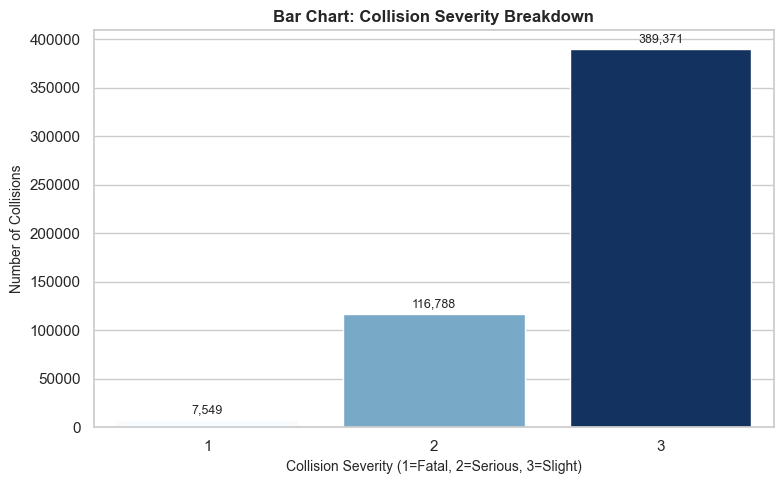

In [9]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

ax = sns.countplot(x='collision_severity', data=collisions_df, hue='collision_severity', palette='Blues', legend=False, order=[1, 2, 3])
plt.title('Bar Chart: Collision Severity Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Number of Collisions', fontsize=10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

# Reveals a severe class imbalance where "Slight" accidents overwhelmingly dominate the dataset, while "Serious" and "Fatal" incidents represent a small fraction.

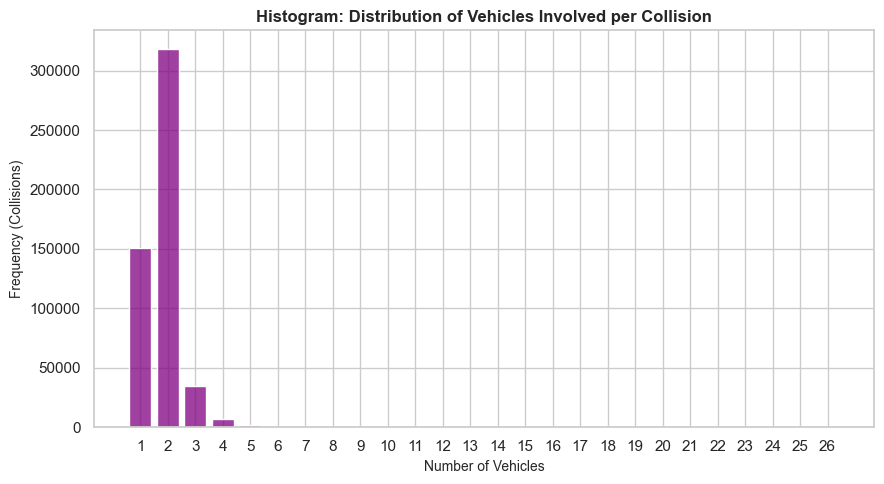

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(collisions_df['number_of_vehicles'], discrete=True, color='purple', shrink=0.8)
plt.title('Histogram: Distribution of Vehicles Involved per Collision', fontsize=12, fontweight='bold')
plt.xlabel('Number of Vehicles', fontsize=10)
plt.ylabel('Frequency (Collisions)', fontsize=10)

# Fix x-axis ticks to only show whole numbers based on the actual data range
max_vehicles = int(collisions_df['number_of_vehicles'].max())
plt.xticks(range(1, max_vehicles + 1))

plt.tight_layout()
plt.show(

)

# Purpose: To examine the structural complexity of accidents by checking whether crashes involve single vehicles or multi-vehicle chains.

# Inference: Demonstrates that the vast majority of collisions involve either 1 or 2 vehicles, indicating that most road incidents stem from single-vehicle driver errors or two-car interactions rather than massive multi-vehicle pileups.

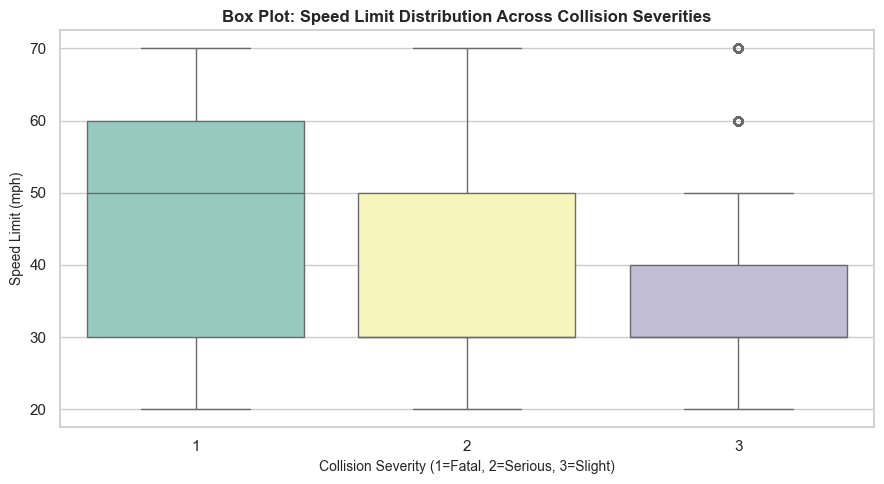

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(x='collision_severity', y='speed_limit', data=collisions_df, palette='Set3', order=[1, 2, 3], hue='collision_severity', legend=False)
plt.title('Box Plot: Speed Limit Distribution Across Collision Severities', fontsize=12, fontweight='bold')
plt.xlabel('Collision Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Speed Limit (mph)', fontsize=10)

plt.tight_layout()
plt.show()

# Highlights that fatal and serious accidents frequently map to higher-speed zones (such as rural 50–60 mph roads), whereas slight accidents cluster heavily in urban 30 mph zones, confirming speed as a primary risk factor.

2. Vehicle Dataset EDA

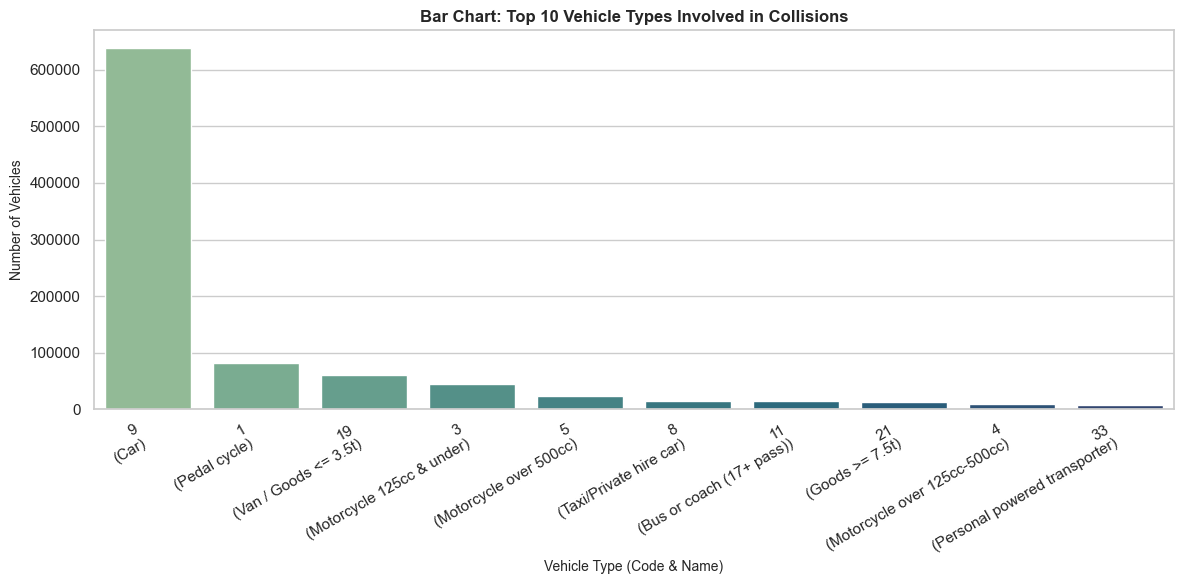

In [12]:
# Mapping vehicle type codes to descriptive text labels
vehicle_mapping = {
    1: 'Pedal cycle',
    2: 'Motorcycle 50cc & under',
    3: 'Motorcycle 125cc & under',
    4: 'Motorcycle over 125cc-500cc',
    5: 'Motorcycle over 500cc',
    8: 'Taxi/Private hire car',
    9: 'Car',
    10: 'Minibus (8-16 pass)',
    11: 'Bus or coach (17+ pass)',
    16: 'Ridden horse',
    17: 'Agricultural vehicle',
    18: 'Tram',
    19: 'Van / Goods <= 3.5t',
    20: 'Goods > 3.5t & < 7.5t',
    21: 'Goods >= 7.5t',
    22: 'Mobility scooter',
    23: 'Electric motorcycle',
    33: 'Personal powered transporter',
    90: 'Other vehicle',
    97: 'Motorcycle - unknown cc',
    98: 'Goods vehicle - unknown weight',
    99: 'Unknown vehicle type',
    103: 'Motorcycle - Scooter (1979-1998)',
    104: 'Motorcycle (1979-1998)',
    105: 'Motorcycle - Combination (1979-1998)',
    106: 'Motorcycle over 125cc (1999-2004)',
    108: 'Taxi (excl. private hire) (1979-2004)',
    109: 'Car (incl. private hire) (1979-2004)',
    110: 'Minibus/Motor caravan (1979-1998)',
    113: 'Goods over 3.5 tonnes (1979-1998)'
}

plt.figure(figsize=(12, 6))

# Top 10 vehicle types
top_vehicles = vehicles_df['vehicle_type'].value_counts().head(10).reset_index()
top_vehicles.columns = ['vehicle_type', 'count']

# Map numeric codes to labels for display clarity
top_vehicles['vehicle_label'] = top_vehicles['vehicle_type'].map(
    lambda x: f"{x}\n({vehicle_mapping.get(x, 'Unknown')})"
)

ax = sns.barplot(
    data=top_vehicles, 
    x='vehicle_label', 
    y='count', 
    palette='crest', 
    hue='vehicle_label', 
    legend=False
)

plt.title('Bar Chart: Top 10 Vehicle Types Involved in Collisions', fontsize=12, fontweight='bold')
plt.xlabel('Vehicle Type (Code & Name)', fontsize=10)
plt.ylabel('Number of Vehicles', fontsize=10)

# Rotate X-axis labels for better legibility
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

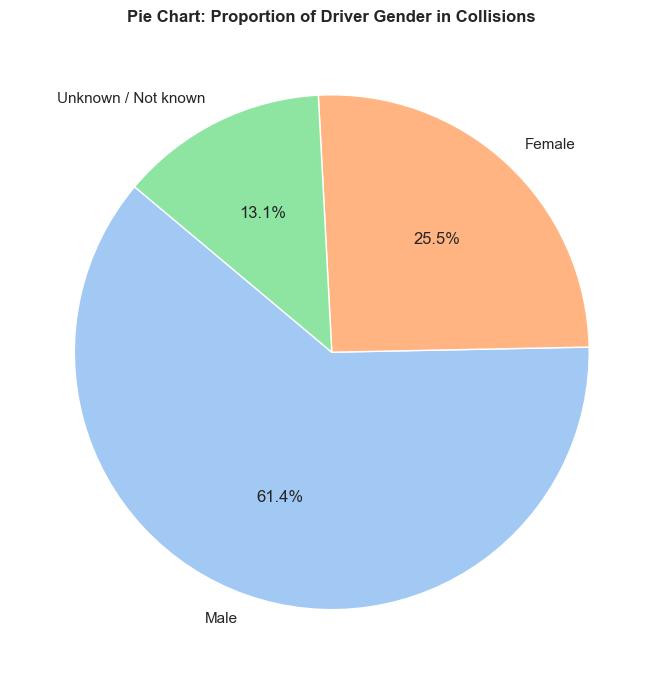

In [13]:
# Mapping gender codes to human-readable labels 
# (Code 3 and any unmapped/missing codes are grouped under 'Unknown / Not known')
gender_mapping = {
    1: 'Male',
    2: 'Female',
    3: 'Unknown / Not known'
}

plt.figure(figsize=(7, 7))

# Filter out invalid placeholder codes like -1
filtered_df = vehicles_df[vehicles_df['sex_of_driver'] != -1].copy()

# Map numeric codes to descriptive labels, filling any missing mappings as 'Unknown'
filtered_df['gender_label'] = filtered_df['sex_of_driver'].map(gender_mapping).fillna('Unknown / Not known')

# Count occurrences of each category
gender_counts = filtered_df['gender_label'].value_counts()

# Plotting the pie chart
plt.pie(
    gender_counts, 
    labels=gender_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)

plt.title('Pie Chart: Proportion of Driver Gender in Collisions', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

3. Casualties Dataset EDA


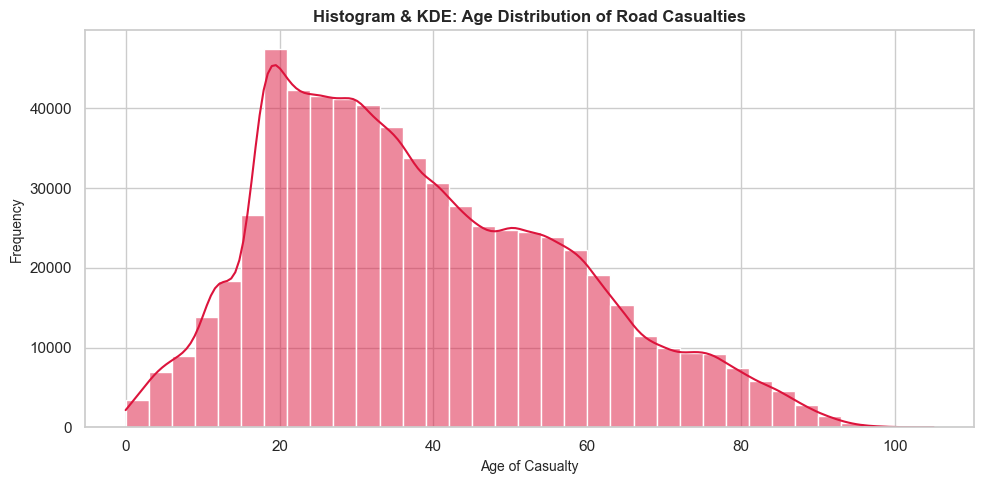

In [14]:
plt.figure(figsize=(10, 5))

# Convert column to numeric, turning strings like "Unknown" into NaN, then drop NaNs
age_data = pd.to_numeric(casualties_df['age_of_casualty'], errors='coerce').dropna()

sns.histplot(age_data, bins=35, kde=True, color='crimson')
plt.title('Histogram & KDE: Age Distribution of Road Casualties', fontsize=12, fontweight='bold')
plt.xlabel('Age of Casualty', fontsize=10)
plt.ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

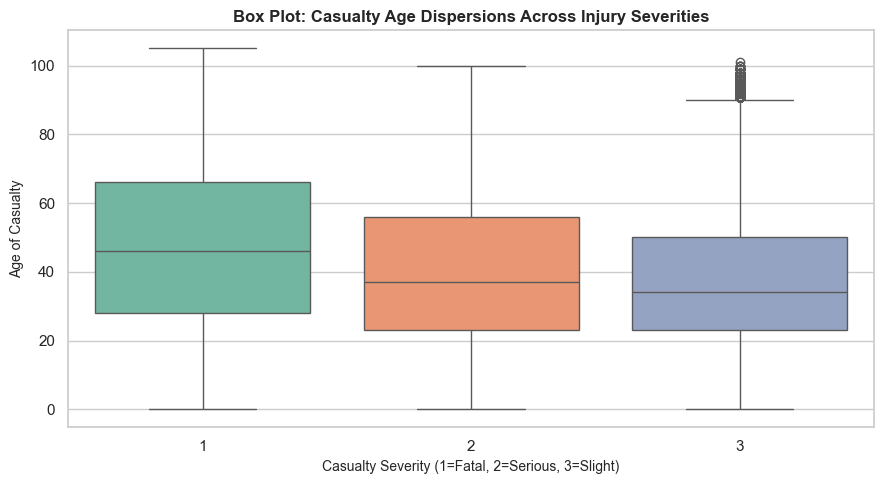

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure age of casualty is numeric (coercing any text like 'Unknown' to NaN)
casualties_df['age_of_casualty'] = pd.to_numeric(casualties_df['age_of_casualty'], errors='coerce')

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=casualties_df, 
    x='casualty_severity', 
    y='age_of_casualty', 
    palette='Set2', 
    order=[1, 2, 3], 
    hue='casualty_severity', 
    legend=False
)

plt.title('Box Plot: Casualty Age Dispersions Across Injury Severities', fontsize=12, fontweight='bold')
plt.xlabel('Casualty Severity (1=Fatal, 2=Serious, 3=Slight)', fontsize=10)
plt.ylabel('Age of Casualty', fontsize=10)

plt.tight_layout()
plt.show()

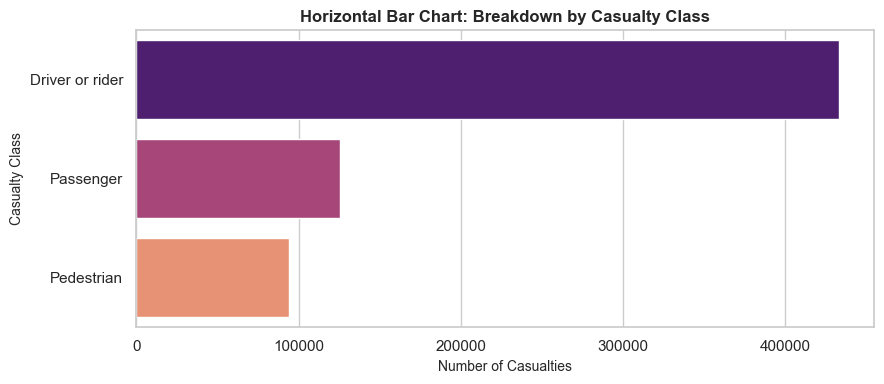

In [16]:
# Mapping casualty class codes to descriptive labels
class_mapping = {
    1: 'Driver or rider',
    2: 'Passenger',
    3: 'Pedestrian'
}

plt.figure(figsize=(9, 4))

# Count occurrences and map labels
class_counts = casualties_df['casualty_class'].value_counts().reset_index()
class_counts.columns = ['casualty_class', 'count']
class_counts['class_label'] = class_counts['casualty_class'].map(class_mapping)

ax = sns.barplot(
    data=class_counts, 
    x='count', 
    y='class_label', 
    palette='magma', 
    hue='class_label', 
    legend=False
)

plt.title('Horizontal Bar Chart: Breakdown by Casualty Class', fontsize=12, fontweight='bold')
plt.xlabel('Number of Casualties', fontsize=10)
plt.ylabel('Casualty Class', fontsize=10)

plt.tight_layout()
plt.show()

Merging 3 Datasets into One dataset - 1 row per collision (transaction) => collision_index as primary merging key

In [17]:
import pandas as pd

# Dictionary of your datasets for easy inspection
datasets = {
    "Collisions DataFrame": collisions_df,
    "Vehicles DataFrame": vehicles_df,
    "Casualties DataFrame": casualties_df
}

# Loop through each dataset to show column names and count
for name, df in datasets.items():
    print(f"--- {name} ---")
    print(f"Total Columns: {df.shape[1]}")
    print("Columns:")
    for col in df.columns:
        print(f"  - {col}")
    print("\n" + "="*40 + "\n")

--- Collisions DataFrame ---
Total Columns: 35
Columns:
  - collision_index
  - collision_year
  - collision_ref_no
  - location_easting_osgr
  - location_northing_osgr
  - longitude
  - latitude
  - police_force
  - collision_severity
  - number_of_vehicles
  - number_of_casualties
  - date
  - day_of_week
  - time
  - local_authority_ons_district
  - local_authority_highway
  - local_authority_highway_current
  - first_road_class
  - first_road_number
  - road_type
  - speed_limit
  - junction_detail
  - second_road_class
  - pedestrian_crossing
  - light_conditions
  - weather_conditions
  - road_surface_conditions
  - carriageway_hazards
  - urban_or_rural_area
  - did_police_officer_attend_scene_of_accident
  - trunk_road_flag
  - lsoa_of_accident_location
  - collision_injury_based
  - collision_adjusted_severity_serious
  - collision_adjusted_severity_slight


--- Vehicles DataFrame ---
Total Columns: 24
Columns:
  - collision_index
  - collision_year
  - collision_ref_no
  - ve

In [18]:
# ============================================================
# GOAL: 1 row = 1 collision.
# Vehicles and casualties have MANY rows per collision, so we first
# squash each of them to ONE row per collision_index, then attach
# the squashed tables to the collisions table.
# ============================================================

# ---- 0. Work on copies (coordinates already cleaned beforehand) ----
col = collisions_df.copy()
veh = vehicles_df.copy()
cas = casualties_df.copy()

# ---- 1. Make the join key identical in all three tables ----
for d in (col, veh, cas):
    d["collision_index"] = d["collision_index"].astype("string").str.strip()

assert col["collision_index"].is_unique, "Collision IDs are not unique!"

# ---- 2. VEHICLES -> one row per collision ----
# 'Unknown' (text) becomes NaN here, so it can never break a comparison
veh["driver_age"] = pd.to_numeric(veh["age_of_driver"], errors="coerce").where(lambda s: s.between(16, 100))

MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV = {20, 21, 98, 113}
BUS = {11}          # 108 / 109 are old taxi / car codes, not buses

veh["is_motorcycle"] = veh["vehicle_type"].isin(MOTORCYCLE)
veh["is_hgv"] = veh["vehicle_type"].isin(HGV)
veh["is_bus"] = veh["vehicle_type"].isin(BUS)
veh["is_cycle"] = veh["vehicle_type"].eq(1)
veh["is_van"] = veh["vehicle_type"].eq(19)

vehicle_summary = veh.groupby("collision_index").agg(
    vehicle_records=("vehicle_reference", "count"),
    distinct_vehicle_types=("vehicle_type", "nunique"),
    mean_driver_age=("driver_age", "mean"),
    motorcycle_involved=("is_motorcycle", "any"),
    hgv_involved=("is_hgv", "any"),
    bus_involved=("is_bus", "any"),
    cycle_involved=("is_cycle", "any"),
    van_involved=("is_van", "any"),
)

# ---- 3. CASUALTIES -> one row per collision ----
cas["casualty_age"] = pd.to_numeric(cas["age_of_casualty"], errors="coerce").where(lambda s: s.between(0, 110))

cas["is_pedestrian"] = cas["casualty_class"].eq(3)
cas["is_child"] = cas["age_band_of_casualty"].isin([1, 2, 3])      # 0-15
cas["is_elderly"] = cas["age_band_of_casualty"].isin([10, 11])     # 66+

casualty_summary = cas.groupby("collision_index").agg(
    casualty_records=("casualty_reference", "count"),
    mean_casualty_age=("casualty_age", "mean"),
    youngest_casualty_age=("casualty_age", "min"),
    pedestrian_casualty=("is_pedestrian", "any"),
    child_casualty=("is_child", "any"),
    elderly_casualty=("is_elderly", "any"),
)

# how many casualties of each severity (1=Fatal, 2=Serious, 3=Slight) per collision
sev_counts = pd.crosstab(cas["collision_index"], cas["casualty_severity"])
sev_counts.columns = [f"casualties_severity_code_{int(c)}" for c in sev_counts.columns]
casualty_summary = casualty_summary.join(sev_counts, how="left")

# ---- 4. MERGE: collisions + vehicle_summary + casualty_summary ----
rows_before = len(col)

df_merged = (
    col
    .merge(vehicle_summary, left_on="collision_index", right_index=True,
            how="left", validate="one_to_one")
    .merge(casualty_summary, left_on="collision_index", right_index=True,
            how="left", validate="one_to_one")
)

# ---- 5. SANITY CHECKS ----
print("Rows before merge:", rows_before)
print("Rows after merge :", len(df_merged))            # must be identical
print("Unique collisions:", df_merged["collision_index"].nunique())
print("Collisions with no vehicle rows  :", df_merged["vehicle_records"].isna().sum())
print("Collisions with no casualty rows :", df_merged["casualty_records"].isna().sum())
print("number_of_vehicles != vehicle_records   :",
      (df_merged["number_of_vehicles"] != df_merged["vehicle_records"]).sum())
print("number_of_casualties != casualty_records:",
      (df_merged["number_of_casualties"] != df_merged["casualty_records"]).sum())
print("Shape:", df_merged.shape)

display(df_merged.head(3))


Rows before merge: 513708
Rows after merge : 513708
Unique collisions: 513708
Collisions with no vehicle rows  : 0
Collisions with no casualty rows : 0
number_of_vehicles != vehicle_records   : 0
number_of_casualties != casualty_records: 0
Shape: (513708, 52)


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,van_involved,casualty_records,mean_casualty_age,youngest_casualty_age,pedestrian_casualty,child_casualty,elderly_casualty,casualties_severity_code_1,casualties_severity_code_2,casualties_severity_code_3
0,202417H105824,2024,17H105824,448628.0,533968.0,-1.24700,54.69840,17,2,2,...,False,1,33.000000,33.0,False,False,False,0,1,0
1,202517M115025,2025,17M115025,452379.0,519038.0,-1.19147,54.56387,17,2,2,...,False,1,17.000000,17.0,False,False,False,0,1,0
2,202517L306225,2025,17L306225,459273.0,523811.0,-1.08390,54.60600,17,3,2,...,True,3,19.666667,10.0,False,True,False,0,0,3


In [19]:
# Check missing value counts and percentages in the merged dataset
missing_df = pd.DataFrame({
    'Missing Count': df_merged.isna().sum(),
    'Missing Percentage (%)': (df_merged.isna().sum() / len(df_merged)) * 100
}).sort_values(by='Missing Count', ascending=False)

display(missing_df[missing_df['Missing Count'] > 0].head(15))

,Missing Count,Missing Percentage (%)
mean_driver_age,30394,5.916591
mean_casualty_age,8391,1.633418
youngest_casualty_age,8391,1.633418


In [20]:
# ---- 6. HANDLING MISSING VALUES FOR AGES ----
# Impute missing aggregate age columns using the median to protect against skewness
df_merged["mean_driver_age"] = df_merged["mean_driver_age"].fillna(df_merged["mean_driver_age"].median())
df_merged["mean_casualty_age"] = df_merged["mean_casualty_age"].fillna(df_merged["mean_casualty_age"].median())
df_merged["youngest_casualty_age"] = df_merged["youngest_casualty_age"].fillna(df_merged["youngest_casualty_age"].median())

# Verification check
print("Total missing values remaining in df_merged:", df_merged.isna().sum().sum())
print("Updated dataset shape:", df_merged.shape)

Total missing values remaining in df_merged: 0
Updated dataset shape: (513708, 52)


EDA on Merged Dataset

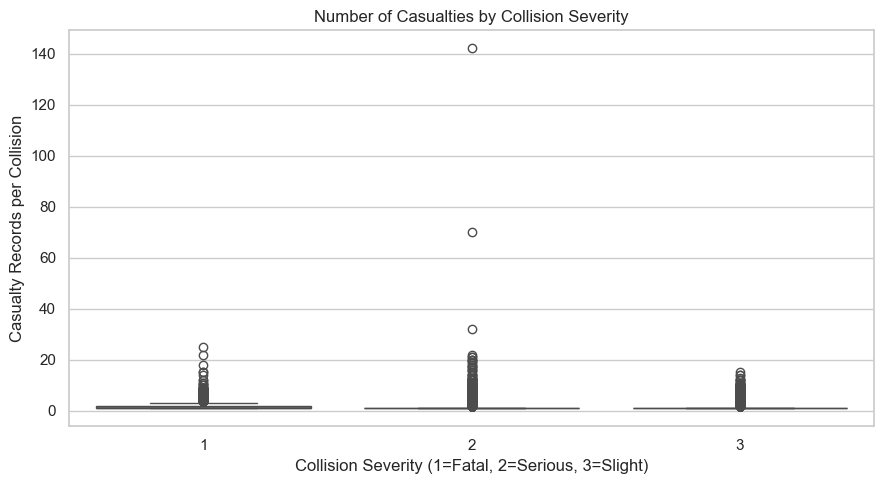

In [21]:
# EDA on Merged dataset
# 1. Collision severity versus number of casualties

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_merged,
    x="collision_severity",
    y="casualty_records"
)
plt.title("Number of Casualties by Collision Severity")
plt.xlabel("Collision Severity (1=Fatal, 2=Serious, 3=Slight)")
plt.ylabel("Casualty Records per Collision")
plt.tight_layout()
plt.show()




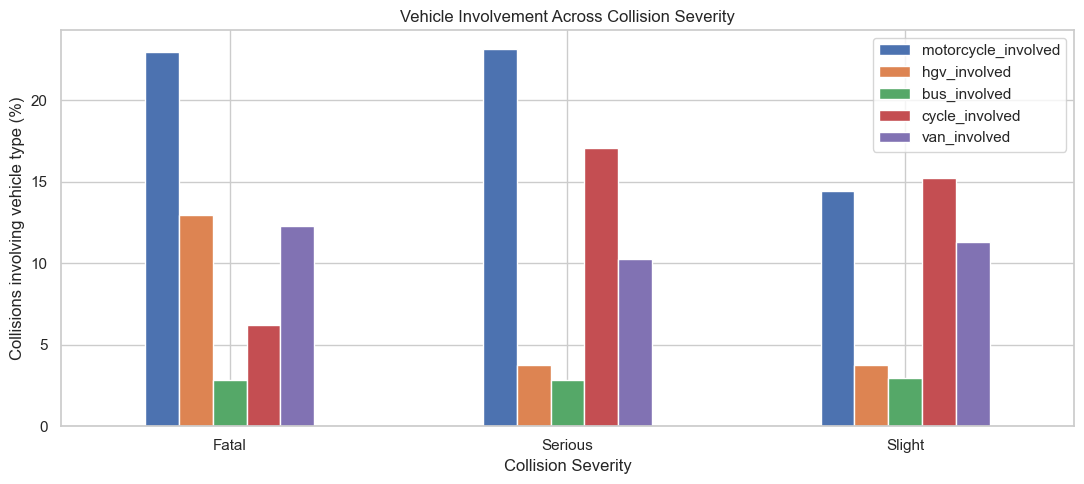

In [22]:
# 2. Severity versus involvement of different vehicle types

vehicle_flags = [
    "motorcycle_involved", "hgv_involved", "bus_involved",
    "cycle_involved", "van_involved"
]

severity_by_vehicle = df_merged.groupby(
    "collision_severity"
)[vehicle_flags].mean() * 100

severity_by_vehicle.index = severity_by_vehicle.index.map({
    1: "Fatal", 2: "Serious", 3: "Slight"
})

severity_by_vehicle.plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Vehicle Involvement Across Collision Severity")
plt.xlabel("Collision Severity")
plt.ylabel("Collisions involving vehicle type (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()




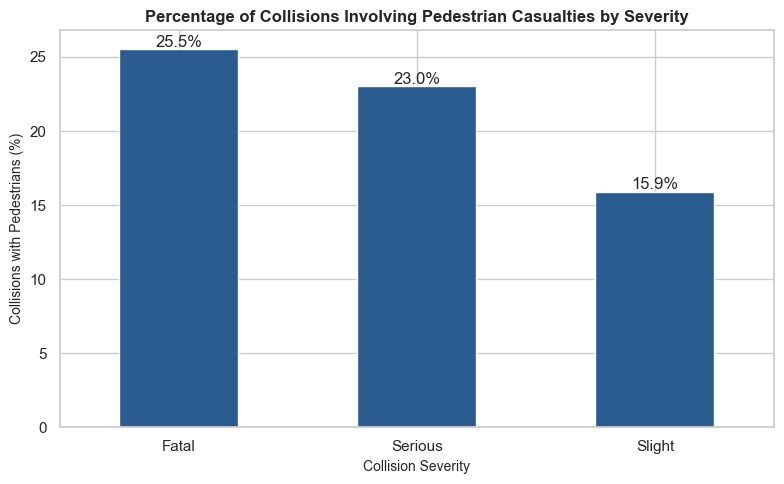

In [24]:
# Calculate the percentage of collisions involving pedestrian casualties by severity
pedestrian_rates = (
    df_merged.groupby("collision_severity")["pedestrian_casualty"]
    .mean() * 100
)
pedestrian_rates.index = ["Fatal", "Serious", "Slight"]

# Now run your plotting code (Cell 30):
ax = pedestrian_rates.plot(kind="bar", figsize=(8, 5), color="#2b5c8f")

plt.title("Percentage of Collisions Involving Pedestrian Casualties by Severity", fontsize=12, fontweight='bold')
plt.xlabel("Collision Severity", fontsize=10)
plt.ylabel("Collisions with Pedestrians (%)", fontsize=10)
plt.xticks(ticks=[0, 1, 2], labels=["Fatal", "Serious", "Slight"], rotation=0)

# Add percentage labels on top of each bar for clarity
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points')

plt.tight_layout()
plt.show()

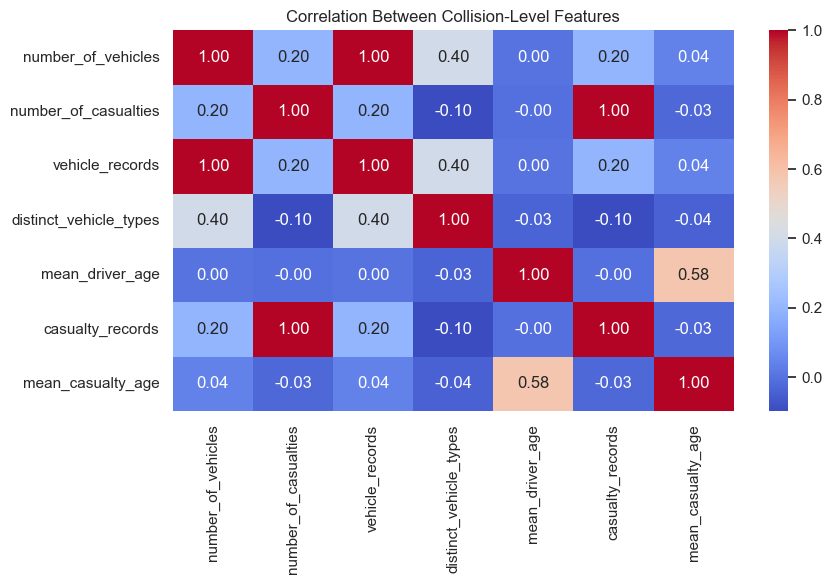

In [25]:
# 5. Correlation among selected numerical features

numeric_cols = [
    "number_of_vehicles", "number_of_casualties",
    "vehicle_records", "distinct_vehicle_types",
    "mean_driver_age", "casualty_records",
    "mean_casualty_age"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df_merged[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Collision-Level Features")
plt.tight_layout()
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_11188\821971071.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


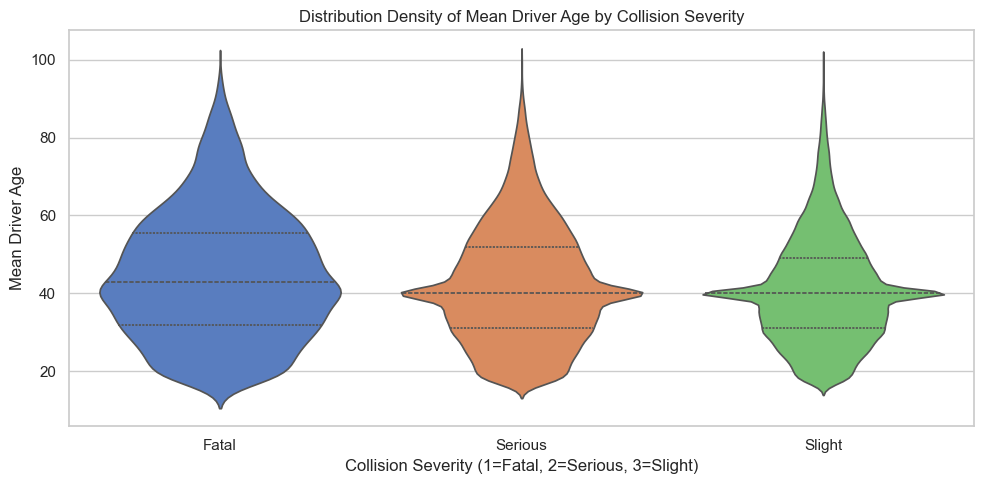

In [27]:
# Revealing Distribution Density & Tails
plt.figure(figsize=(10, 5))
sns.violinplot(
    data=df_merged,
    x="collision_severity",
    y="mean_driver_age",
    palette="muted",
    inner="quart"
)
plt.title("Distribution Density of Mean Driver Age by Collision Severity")
plt.xlabel("Collision Severity (1=Fatal, 2=Serious, 3=Slight)")
plt.ylabel("Mean Driver Age")
plt.xticks([0, 1, 2], ["Fatal", "Serious", "Slight"])
plt.tight_layout()
plt.show()

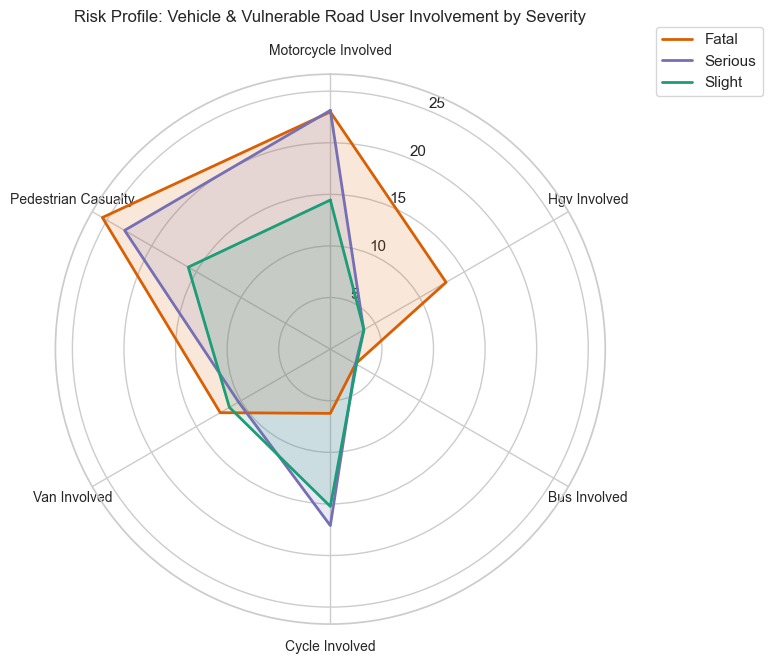

In [28]:
# 1. Define features and data
radar_features = [
    "motorcycle_involved", "hgv_involved", "bus_involved", 
    "cycle_involved", "van_involved", "pedestrian_casualty"
]

severity_profiles = df_merged.groupby("collision_severity")[radar_features].mean() * 100
severity_profiles.index = ["Fatal", "Serious", "Slight"]

labels = [f.replace("_", " ").title() for f in radar_features]
num_vars = len(labels)

# 2. Generate exact angles for the 6 categories
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False)
# Create a closed-loop version for polygon plotting (repeating the first angle at the end)
plot_angles = np.append(angles, angles[0])

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

colors = {
    "Fatal": "#d95f02", 
    "Serious": "#7570b3", 
    "Slight": "#1b9e77"
}

for severity_label, row in severity_profiles.iterrows():
    values = row.values.flatten().tolist()
    # Close the loop for values as well
    values.append(values[0])
    
    ax.plot(plot_angles, values, linewidth=2, linestyle='solid', label=severity_label, color=colors[severity_label])
    ax.fill(plot_angles, values, color=colors[severity_label], alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# 3. Explicitly map the 6 tick angles to the 6 labels
ax.set_xticks(angles)
ax.set_xticklabels(labels, fontsize=10)

ax.set_title("Risk Profile: Vehicle & Vulnerable Road User Involvement by Severity", y=1.08, fontsize=12)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

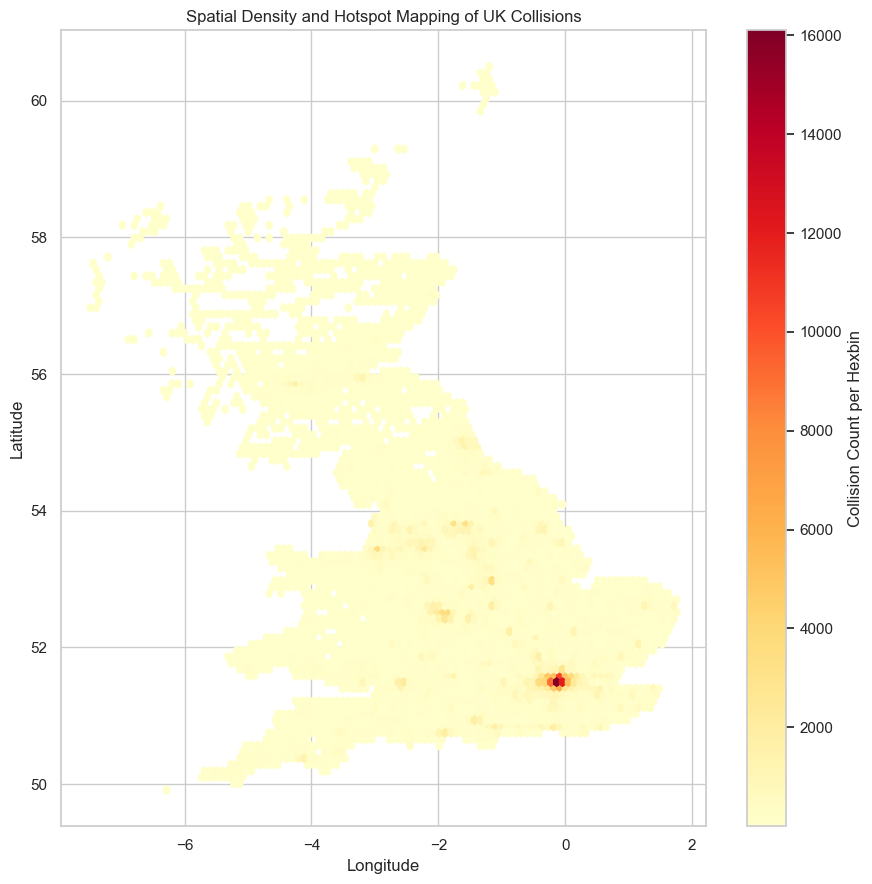

In [29]:
# Accident Density Hotspots

plt.figure(figsize=(9, 9))
plt.hexbin(
    df_merged["longitude"], 
    df_merged["latitude"], 
    gridsize=100, 
    cmap="YlOrRd", 
    mincnt=1
)
cb = plt.colorbar(label="Collision Count per Hexbin")
plt.title("Spatial Density and Hotspot Mapping of UK Collisions")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

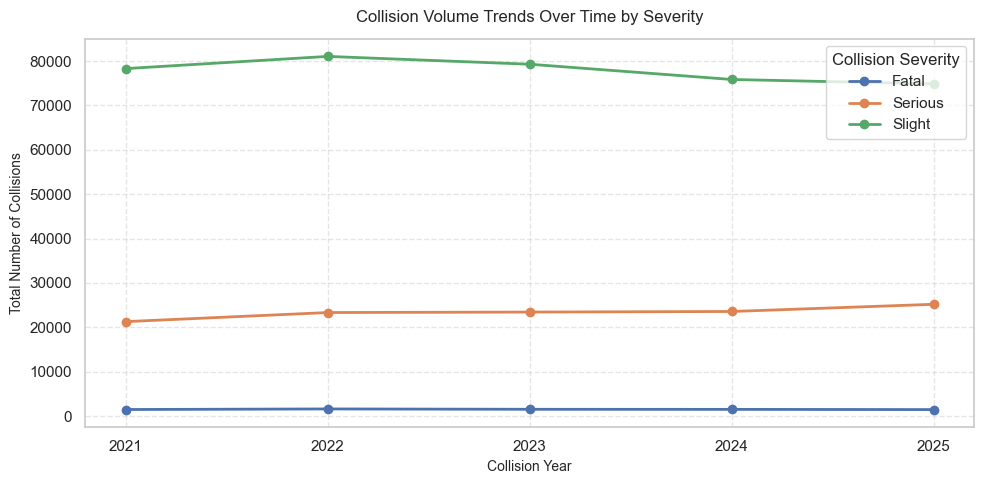

In [30]:
# Temporal Trend: Collisions over Years broken down by Severity
if "collision_year" in df_merged.columns:
    # Group by year and severity, then pivot to get severity levels as columns
    yearly_severity = df_merged.groupby(["collision_year", "collision_severity"]).size().unstack(fill_value=0)
    
    # Map severity codes to descriptive labels
    yearly_severity.columns = ["Fatal", "Serious", "Slight"]
    
    # Plotting the trend lines
    plt.figure(figsize=(10, 5))
    ax = yearly_severity.plot(kind="line", marker="o", linewidth=2, figsize=(10, 5))
    
    plt.title("Collision Volume Trends Over Time by Severity", fontsize=12, pad=12)
    plt.xlabel("Collision Year", fontsize=10)
    plt.ylabel("Total Number of Collisions", fontsize=10)
    plt.legend(title="Collision Severity", loc="upper right")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.xticks(yearly_severity.index)
    plt.tight_layout()
    plt.show()
else:
    print("Column 'collision_year' not found in df_merged.")

Preparing data for Pattern Mining


In [31]:
import numpy as np, pandas as pd

# =====================================================================
# BUILD TRANSACTIONS (1 row = 1 collision, 1 column = 1 item)
# All code -> label mappings checked against the DfT 2024 code list
# (dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx)
# =====================================================================

col = collisions_df.set_index('collision_index')
veh = vehicles_df
cas = casualties_df


def num(series):
    """Force numeric: text such as 'Unknown' (from the earlier -1 replacement) becomes NaN."""
    return pd.to_numeric(series, errors='coerce')


def m(series, mapping, name):
    """code -> 'Name=Label'. Codes not in mapping (unknown / missing / other) -> NaN (no item)."""
    return num(series).map(mapping).map(lambda v: f"{name}={v}" if pd.notna(v) else np.nan)


items = pd.DataFrame(index=col.index)

# ---- target ----
items['sev'] = m(col['collision_severity'], {1: 'Fatal', 2: 'Serious', 3: 'Slight'}, 'Severity')

# ---- road / environment ----
# speed_limit: only 20,30,40,50,60,70 are valid (99 = unknown, -1 = missing)
speed = num(col['speed_limit'])
items['speed'] = speed.where(speed.isin([20, 30, 40, 50, 60, 70])).map(
    lambda v: f"Speed={int(v)}mph" if pd.notna(v) else np.nan)

# light: 1 daylight | 4 dark lights lit | 5 dark lights unlit | 6 dark no lighting | 7 dark lighting unknown (skipped)
items['light'] = m(col['light_conditions'],
                   {1: 'Daylight', 4: 'Dark_streetlit', 5: 'Dark_unlit', 6: 'Dark_unlit'}, 'Light')

# weather: 1 fine | 2 rain | 3 snow | 4,5,6 = same + high winds | 7 fog | 8 other, 9 unknown (skipped)
items['weather'] = m(col['weather_conditions'],
                     {1: 'Fine', 2: 'Rain', 3: 'Snow', 4: 'HighWind', 5: 'HighWind', 6: 'HighWind', 7: 'Fog'},
                     'Weather')

# surface: 1 dry | 2 wet | 3 snow | 4 frost/ice | 5 flood | 6 oil, 7 mud, 9 unknown (skipped)
items['surface'] = m(col['road_surface_conditions'],
                     {1: 'Dry', 2: 'Wet', 3: 'Snow_Ice', 4: 'Snow_Ice', 5: 'Flood'}, 'Surface')

# area: 1 urban | 2 rural | 3 unallocated (skipped)
items['area'] = m(col['urban_or_rural_area'], {1: 'Urban', 2: 'Rural'}, 'Area')

# road type: 1 roundabout | 2 one way | 3 dual | 6 single | 7 slip | 12 one way/slip | 9 unknown (skipped)
items['roadtype'] = m(col['road_type'],
                      {1: 'Roundabout', 2: 'OneWay', 3: 'DualCarriageway', 6: 'SingleCarriageway',
                       7: 'SlipRoad', 12: 'OneWay_Slip'}, 'RoadType')

# junction_detail uses the NEW 2024 codes (the old 1,2,3,5,6,7,8,9 codes live in junction_detail_historic)
# 0 none | 13 T/staggered | 16 crossroads | 17 >4 arms | 18 private drive | 19 other | 99 unknown (skipped)
items['junction'] = m(col['junction_detail'],
                      {0: 'None', 13: 'T_or_Staggered', 16: 'Crossroads', 17: 'MultiArm',
                       18: 'PrivateDrive', 19: 'OtherJunction'}, 'Junction')

items['roadclass'] = m(col['first_road_class'],
                       {1: 'Motorway', 2: 'A(M)', 3: 'A', 4: 'B', 5: 'C', 6: 'Unclassified'}, 'RoadClass')

# ---- time ----
hour = pd.to_numeric(col['time'].astype(str).str[:2], errors='coerce')
items['time'] = (pd.cut(hour, bins=[-1, 5, 9, 15, 19, 23],
                        labels=['Night(0-5)', 'MorningPeak(6-9)', 'Midday(10-15)',
                                'EveningPeak(16-19)', 'LateEvening(20-23)'])
                 .astype(object).map(lambda v: f"Time={v}" if pd.notna(v) else np.nan))

# day_of_week: 1 = Sunday ... 7 = Saturday
items['daytype'] = m(col['day_of_week'],
                     {1: 'Weekend', 7: 'Weekend', 2: 'Weekday', 3: 'Weekday',
                      4: 'Weekday', 5: 'Weekday', 6: 'Weekday'}, 'Day')

month = pd.to_datetime(col['date'], dayfirst=True, errors='coerce').dt.month
items['season'] = (month.map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'})
                   .map(lambda v: f"Season={v}" if pd.notna(v) else np.nan))

# ---- size of collision ----
items['nveh'] = (num(col['number_of_vehicles']).clip(upper=3).map({1: '1', 2: '2', 3: '3+'})
                 .map(lambda v: f"Vehicles={v}" if pd.notna(v) else np.nan))
items['ncas'] = (num(col['number_of_casualties']).clip(upper=3).map({1: '1', 2: '2', 3: '3+'})
                 .map(lambda v: f"Casualties={v}" if pd.notna(v) else np.nan))

# ---- vehicle-level -> collision-level flags (item only when True) ----
MOTORCYCLE = {2, 3, 4, 5, 23, 97, 103, 104, 105, 106}
HGV        = {20, 21, 98, 113}
BUS        = {11}                      # 108/109 are old taxi/car codes, NOT buses

v = veh.copy()
vt = num(v['vehicle_type'])
v['f_motorcycle'] = vt.isin(MOTORCYCLE)
v['f_cycle']      = vt.eq(1)
v['f_hgv']        = vt.isin(HGV)
v['f_bus']        = vt.isin(BUS)
v['f_van']        = vt.eq(19)

ab = num(v['age_band_of_driver'])
v['f_young_drv']  = ab.isin([4, 5])        # 16-25
v['f_old_drv']    = ab.isin([10, 11])      # 66+

# 0 = none, 9/99 = "unknown (self reported)", -1 = missing  ->  only the real event codes count
v['f_skid']        = num(v['skidding_and_overturning']).between(1, 5)          # skidded / jackknifed / overturned
v['f_left_road']   = num(v['vehicle_leaving_carriageway']).between(1, 8)       # left carriageway (not 0, not 9)
v['f_hit_offroad'] = num(v['hit_object_off_carriageway']).between(1, 11)       # hit an object (not 0, not 99)

vflags = v.groupby('collision_index')[[c for c in v.columns if c.startswith('f_')]].any()
vnames = {'f_motorcycle': 'Motorcycle_involved', 'f_cycle': 'Cycle_involved', 'f_hgv': 'HGV_involved',
          'f_bus': 'Bus_involved', 'f_van': 'Van_involved', 'f_young_drv': 'YoungDriver(16-25)',
          'f_old_drv': 'OlderDriver(66+)', 'f_skid': 'Skid_or_Overturn',
          'f_left_road': 'LeftCarriageway', 'f_hit_offroad': 'HitObjectOffRoad'}

# ---- casualty-level -> collision-level flags ----
c2 = cas.copy()
cab = num(c2['age_band_of_casualty'])
c2['f_ped_cas']   = num(c2['casualty_class']).eq(3)
c2['f_child_cas'] = cab.isin([1, 2, 3])        # 0-15
c2['f_old_cas']   = cab.isin([10, 11])         # 66+
cflags = c2.groupby('collision_index')[['f_ped_cas', 'f_child_cas', 'f_old_cas']].any()
cnames = {'f_ped_cas': 'Pedestrian_casualty', 'f_child_cas': 'Child_casualty', 'f_old_cas': 'Elderly_casualty'}

# ---- one-hot -> boolean basket ----
cat_part = pd.get_dummies(items, prefix='', prefix_sep='', dtype=bool)
flag_part = (vflags.rename(columns=vnames).reindex(col.index, fill_value=False)
             .join(cflags.rename(columns=cnames).reindex(col.index, fill_value=False)))
basket = pd.concat([cat_part, flag_part], axis=1).astype(bool)

# drop ultra-rare items (<0.1%) - they can never be frequent anyway
keep = basket.columns[basket.mean() >= 0.001]
basket = basket[keep]
N = len(basket)

# ---- checks ----
print("transactions:", N, "| items:", basket.shape[1],
      "| avg items per transaction:", round(basket.sum(axis=1).mean(), 1))
print("\nShare of collisions with NO item in each group (should be small):")
print(items.isna().mean().round(3).to_string())
print("\nItem supports:")
print(basket.mean().sort_values(ascending=False).round(3).to_string())

transactions: 513708 | items: 70 | avg items per transaction: 15.6

Share of collisions with NO item in each group (should be small):
sev          0.000
speed        0.000
light        0.017
weather      0.059
surface      0.020
area         0.000
roadtype     0.025
junction     0.042
roadclass    0.000
time         0.000
daytype      0.000
season       0.000
nveh         0.000
ncas         0.000

Item supports:
Casualties=1                  0.815
Weather=Fine                  0.805
Severity=Slight               0.758
Day=Weekday                   0.750
Surface=Dry                   0.728
RoadType=SingleCarriageway    0.726
Light=Daylight                0.717
Area=Urban                    0.672
Vehicles=2                    0.619
Speed=30mph                   0.520
Junction=None                 0.491
RoadClass=A                   0.440
Time=Midday(10-15)            0.359
RoadClass=Unclassified        0.359
Area=Rural                    0.328
Time=EveningPeak(16-19)       0.295
Vehicles

In [32]:

print("TRANSACTION DATASET VALIDATION")
print("-" * 45)

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Missing cells:", basket.isna().sum().sum())
print("Duplicate collision IDs:", basket.index.duplicated().sum())
print("Duplicate item names:", basket.columns.duplicated().sum())
print("Empty transactions:", (~basket.any(axis=1)).sum())

print("\nMost frequent items (% of transactions):")
display(
    (basket.mean() * 100)
    .sort_values(ascending=False)
    .head(20)
    .round(2)
    .to_frame("support_percent")
)

print("\nTransactions as item lists:")
transactions = [
    basket.columns[row].tolist()
    for row in basket.to_numpy(dtype=bool)
]

for i, transaction in enumerate(transactions[:10], start=1):
    print(f"T{i}: {transaction}")


TRANSACTION DATASET VALIDATION
---------------------------------------------
Transactions: 513708
Items: 70
Missing cells: 0
Duplicate collision IDs: 0
Duplicate item names: 0
Empty transactions: 0

Most frequent items (% of transactions):


,support_percent
Casualties=1,81.51
Weather=Fine,80.51
Severity=Slight,75.80
Day=Weekday,75.02
Surface=Dry,72.85
RoadType=SingleCarriageway,72.61
Light=Daylight,71.67
Area=Urban,67.22
Vehicles=2,61.88
Speed=30mph,52.03



Transactions as item lists:
T1: ['Severity=Serious', 'Speed=30mph', 'Light=Daylight', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'Junction=None', 'RoadClass=Unclassified', 'Time=EveningPeak(16-19)', 'Day=Weekday', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'OlderDriver(66+)']
T2: ['Severity=Serious', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'Junction=T_or_Staggered', 'RoadClass=A', 'Time=EveningPeak(16-19)', 'Day=Weekend', 'Season=Autumn', 'Vehicles=2', 'Casualties=1', 'Cycle_involved', 'YoungDriver(16-25)']
T3: ['Severity=Slight', 'Speed=30mph', 'Light=Dark_streetlit', 'Weather=Fine', 'Surface=Dry', 'Area=Urban', 'RoadType=SingleCarriageway', 'Junction=T_or_Staggered', 'RoadClass=A', 'Time=LateEvening(20-23)', 'Day=Weekend', 'Season=Summer', 'Vehicles=2', 'Casualties=3+', 'Van_involved', 'Child_casualty']
T4: ['Severity=Slight', 'Speed=60mph', 'Light=Daylight

## RUN ARM Algorithms
1. Apriori
2. FP Growth
3. Dynamic Itemset Counting

In [33]:
%pip -q install mlxtend


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\user\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [34]:

import time
import math
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth

# Use your existing Boolean transaction table
assert isinstance(basket, pd.DataFrame), "basket must be a DataFrame"
assert basket.shape[0] > 0, "basket has no transactions"
assert basket.shape[1] > 0, "basket has no items"
assert basket.index.is_unique, "basket must have unique collision IDs"
assert not basket.isna().any().any(), "basket contains missing values"

# Ensure Boolean format
basket = basket.astype(bool)

MIN_SUPPORT = 0.04
MIN_SUPPORT_COUNT = math.ceil(MIN_SUPPORT * len(basket))

print("Transactions:", len(basket))
print("Items:", basket.shape[1])
print("Minimum support:", MIN_SUPPORT)
print("Minimum support count:", MIN_SUPPORT_COUNT)
print("Average items per transaction:",
      round(basket.sum(axis=1).mean(), 2))
print("Maximum possible frequent itemset size:", basket.shape[1])

Transactions: 513708
Items: 70
Minimum support: 0.04
Minimum support count: 20549
Average items per transaction: 15.56
Maximum possible frequent itemset size: 70


Run Apriori

In [35]:
def run_apriori(transactions, min_support):
    start = time.perf_counter()

    result = apriori(
        transactions,
        min_support=min_support,
        use_colnames=True,
        low_memory=True
    )

    elapsed = time.perf_counter() - start

    if not result.empty:
        result["itemset_size"] = result["itemsets"].apply(len)
        result = result.sort_values(
            ["itemset_size", "support"],
            ascending=[True, False]
        ).reset_index(drop=True)

    return result, elapsed


apriori_result, apriori_time = run_apriori(basket, MIN_SUPPORT)

print("Apriori runtime:", round(apriori_time, 4), "seconds")
print("Frequent itemsets:", len(apriori_result))

# display(apriori_result.head(30))

Apriori runtime: 349.2833 seconds
Frequent itemsets: 30458


In [ ]:
# # Save Apriori results to Google Drive
# apriori_result.to_pickle(
#     "./apriori_result.pkl"
# )

# print("Apriori results saved!")

Apriori results saved!


In [36]:
if not apriori_result.empty:
    itemset_lengths = apriori_result["itemsets"].apply(len)

    print("Total Frequent Itemsets:", len(apriori_result))
    print("Maximum Length of FI:", itemset_lengths.max())
    print("Minimum Length of FI:", itemset_lengths.min())
else:
    print("No frequent itemsets found.")
    

print("\nFrequent Itemsets by Length:")
print(
    apriori_result["itemsets"]
    .apply(len)
    .value_counts()
    .sort_index()
)

Total Frequent Itemsets: 30458
Maximum Length of FI: 10
Minimum Length of FI: 1

Frequent Itemsets by Length:
itemsets
1       56
2      705
3     3256
4     6991
5     8288
6     6548
7     3396
8     1047
9      163
10       8
Name: count, dtype: int64


In [37]:
import itertools
import pandas as pd


def fmt(s):
    return "{" + ", ".join(sorted(s)) + "}"


# ---------- 1) readable CSV (same as before, but items shown as {A, B}) ----------
apriori_out = apriori_result.copy()
apriori_out["itemsets"] = apriori_out["itemsets"].apply(fmt)
apriori_out["support"] = apriori_out["support"].round(6)
apriori_out.to_csv("./apriori_result.csv", index=False)
print("Saved apriori_result.csv:", len(apriori_out), "itemsets")

sup = dict(zip(apriori_result["itemsets"], apriori_result["support"]))      # frozenset -> support

# ---------- 2) a "typical collision": the longest frequent patterns ----------
longest = apriori_result["itemset_size"].max()
print(f"\nMOST COMMON {longest}-ITEM PATTERNS (profile of a typical collision)")
top_long = (apriori_result[apriori_result["itemset_size"] == longest]
            .sort_values("support", ascending=False).head(5))
for i, r in enumerate(top_long.itertuples(), 1):
    print(f"{i}. {fmt(r.itemsets)}   support {r.support:.1%}")


# ---------- 3) severity patterns taken from the itemsets of ALL lengths ----------
def severity_rules(severity, min_lift=1.15, max_ante=5, gap=0.97, top=10):
    """{A, B, ...} -> {severity}, strongest first, without redundant longer versions."""
    s_item = frozenset([severity])
    s_sup = sup[s_item]
    rules = {}
    for itemset, s in sup.items():
        if severity in itemset and 2 <= len(itemset) <= max_ante + 1:
            ante = itemset - s_item
            if any(x.startswith("Severity=") for x in ante):
                continue
            conf = s / sup[ante]
            rules[ante] = (s, conf, conf / s_sup)

    rows = []
    for ante, (s, conf, lift) in rules.items():
        if lift < min_lift:
            continue
        redundant = any(rules.get(frozenset(sub), (0, 0, 0))[2] >= gap * lift
                        for r in range(1, len(ante))
                        for sub in itertools.combinations(ante, r))
        if not redundant:
            rows.append((ante, s, conf, lift))
    rows.sort(key=lambda x: -x[3])
    return rows[:top]


for sev in ["Severity=Fatal", "Severity=Serious", "Severity=Slight"]:
    print("\n" + "=" * 80)
    if frozenset([sev]) not in sup:
        print(f"{sev.upper()}: not frequent at this minimum support, so it cannot appear in these itemsets")
        print("(use the severity-pattern cell that mines inside each severity class)")
        continue
    base = sup[frozenset([sev])]
    print(f"{sev.upper()}  (baseline: {base:.1%} of all collisions)")
    print("=" * 80)
    for i, (ante, s, conf, lift) in enumerate(severity_rules(sev), 1):
        print(f"{i:>2}. {fmt(ante)}  ->  {{{sev}}}")
        print(f"      support {s:.1%} | confidence {conf:.0%} | lift {lift:.2f}")

Saved apriori_result.csv: 30458 itemsets

MOST COMMON 10-ITEM PATTERNS (profile of a typical collision)
1. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 6.6%
2. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Weather=Fine}   support 5.4%
3. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Time=Midday(10-15), Weather=Fine}   support 4.8%
4. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.4%
5. {Area=Urban, Casualties=1, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.2%

In [38]:
# top 5 paterns of each length
import pandas as pd
import matplotlib.pyplot as plt

# ---- load the Apriori itemsets (uses the table in memory; falls back to the CSV) ----
try:
    df = apriori_result.copy()
    df["iset"] = df["itemsets"].apply(frozenset)
except NameError:
    df = pd.read_csv("apriori_result.csv")
    df["iset"] = df["itemsets"].apply(lambda s: frozenset(x.strip() for x in s.strip("{}").split(", ")))

single = {next(iter(k)): v for k, v in zip(df["iset"], df["support"]) if len(k) == 1}
fmt = lambda s: "{" + ", ".join(sorted(s)) + "}"


def lift_of(items, support):
    """How many times more often the items occur together than if they were independent."""
    p = 1.0
    for i in items:
        p *= single[i]
    return support / p


def top_patterns(top=5, lengths=None, must_contain=None):
    """Print the top patterns of each length, most frequent first.
    must_contain: only patterns that include this item, e.g. 'Severity=Serious'."""
    d = df if must_contain is None else df[df["iset"].apply(lambda s: must_contain in s)]
    for k in (lengths or sorted(d["itemset_size"].unique())):
        sub = d[d["itemset_size"] == k].sort_values("support", ascending=False)
        if sub.empty:
            continue
        print("=" * 100)
        print(f"LENGTH {k}: top {min(top, len(sub))} of {len(sub):,} frequent patterns"
              + (f" containing {must_contain}" if must_contain else ""))
        print("=" * 100)
        for i, r in enumerate(sub.head(top).itertuples(), 1):
            extra = f" | lift {lift_of(r.iset, r.support):.2f}" if k > 1 else ""
            print(f"{i:>2}. {fmt(r.iset)}")
            print(f"      support {r.support:.1%}{extra}")


def plot_top(length, top=5, must_contain=None):
    d = df[df["itemset_size"] == length]
    if must_contain:
        d = d[d["iset"].apply(lambda s: must_contain in s)]
    d = d.sort_values("support", ascending=False).head(top).iloc[::-1]
    labels = [fmt(s) if len(fmt(s)) < 110 else fmt(s)[:107] + "..." for s in d["iset"]]
    fig, ax = plt.subplots(figsize=(13, 0.55 * len(d) + 1.5))
    ax.barh(labels, d["support"] * 100, color="#2e86c1")
    for y, v in enumerate(d["support"]):
        ax.text(v * 100 + 0.1, y, f"{v:.1%}", va="center", fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Support (% of all collisions)")
    ax.set_title(f"Top {len(d)} patterns of length {length}" + (f" containing {must_contain}" if must_contain else ""))
    plt.tight_layout(); plt.show()


top_patterns(top=5)                                          # every length, top 5
top_patterns(top=5, must_contain="Severity=Serious")      # only patterns that include Serious


LENGTH 1: top 5 of 56 frequent patterns
 1. {Casualties=1}
      support 81.5%
 2. {Weather=Fine}
      support 80.5%
 3. {Severity=Slight}
      support 75.8%
 4. {Day=Weekday}
      support 75.0%
 5. {Surface=Dry}
      support 72.8%
LENGTH 2: top 5 of 705 frequent patterns
 1. {Surface=Dry, Weather=Fine}
      support 68.9% | lift 1.18
 2. {Casualties=1, Weather=Fine}
      support 65.5% | lift 1.00
 3. {Casualties=1, Severity=Slight}
      support 62.8% | lift 1.02
 4. {Casualties=1, Day=Weekday}
      support 61.9% | lift 1.01
 5. {Severity=Slight, Weather=Fine}
      support 60.6% | lift 0.99
LENGTH 3: top 5 of 3,256 frequent patterns
 1. {Casualties=1, Surface=Dry, Weather=Fine}
      support 56.4% | lift 1.18
 2. {Light=Daylight, Surface=Dry, Weather=Fine}
      support 53.8% | lift 1.28
 3. {Severity=Slight, Surface=Dry, Weather=Fine}
      support 52.0% | lift 1.17
 4. {Day=Weekday, Surface=Dry, Weather=Fine}
      support 51.5% | lift 1.17
 5. {RoadType=SingleCarriageway, Su

Run FP Growth

In [40]:
import time, math, itertools
import numpy as np
import pandas as pd


class _FPTree:
    """Minimal FP-tree: node 0 is the root. Nodes are stored in parallel lists for speed."""
    __slots__ = ("item", "parent", "count", "nkids", "children", "header", "branched")

    def __init__(self):
        self.item = [-1]
        self.parent = [-1]
        self.count = [0]
        self.nkids = [0]            # number of children of each node
        self.children = {}          # (parent_node, item) -> child node
        self.header = {}            # item -> list of nodes holding that item
        self.branched = False       # becomes True as soon as any node gets a 2nd child

    def insert(self, path, w):
        node = 0
        item, parent, count, nkids, children, header = (self.item, self.parent, self.count,
                                                        self.nkids, self.children, self.header)
        for it in path:
            key = (node, it)
            child = children.get(key)
            if child is None:
                child = len(item)
                item.append(it); parent.append(node); count.append(0); nkids.append(0)
                if nkids[node]:
                    self.branched = True
                nkids[node] += 1
                children[key] = child
                header.setdefault(it, []).append(child)
            count[child] += w
            node = child


def run_fpgrowth(transactions, min_support, max_len=None, verbose=False):
    """
    FP-Growth from scratch (Standard recursive mining without single-path shortcut).
    Returns (result_df, elapsed_seconds).
    """
    start = time.perf_counter()
    say = (lambda *a: print(f"[{time.perf_counter() - start:7.1f}s]", *a, flush=True)) if verbose else (lambda *a: None)

    columns = list(transactions.columns)
    M = transactions.to_numpy(dtype=bool)
    n, n_items = M.shape
    min_count = math.ceil(min_support * n)
    if max_len is None:
        max_len = n_items
    say(f"start: {n:,} transactions, {n_items} items, min_support={min_support}, min_count={min_count:,}, max_len={max_len}")

    # ---- pass 1: frequent single items, ranked by descending support ----
    cnt1 = M.sum(axis=0)
    order = [int(j) for j in np.argsort(-cnt1, kind="stable") if cnt1[j] >= min_count]
    m = len(order)
    if m == 0:
        return pd.DataFrame(columns=["support", "itemsets", "itemset_size"]), time.perf_counter() - start
    say(f"pass 1 done: {m} frequent items")

    # ---- pass 2: keep only frequent items, merge identical transactions ----
    if m <= 63:                             # fast path: one integer code per transaction
        codes = np.zeros(n, dtype=np.uint64)
        for r, j in enumerate(order):
            codes |= M[:, j].astype(np.uint64) << np.uint64(r)
        uniq, weights = np.unique(codes, return_counts=True)
        shifts = np.arange(m, dtype=np.uint64)
        def decode(a, b):
            bits = ((uniq[a:b, None] >> shifts) & np.uint64(1)).astype(bool)
            return bits
    else:                                   # slower generic path
        sub = np.packbits(M[:, order], axis=1)
        uniq_rows, weights = np.unique(sub, axis=0, return_counts=True)
        uniq = uniq_rows
        def decode(a, b):
            return np.unpackbits(uniq_rows[a:b], axis=1)[:, :m].astype(bool)
    say(f"pass 2 done: {len(uniq):,} distinct transactions")

    tree = _FPTree()
    step = 50000
    for a in range(0, len(uniq), step):
        bits = decode(a, a + step)
        for r, w in zip(bits, weights[a:a + step]):
            tree.insert(np.flatnonzero(r).tolist(), int(w))
    say(f"FP-tree built: {len(tree.item) - 1:,} nodes")

    found = {}   # tuple of ranks -> support count
    top_total = len(tree.header)
    top_done = [0]

    def mine(t, suffix):
        for it, nodes in t.header.items():
            sup = 0
            for nd in nodes:
                sup += t.count[nd]
            new_suffix = suffix + (it,)
            found[new_suffix] = sup
            if len(new_suffix) < max_len:
                base = {}
                parent, item, count = t.parent, t.item, t.count
                for nd in nodes:
                    path, p = [], parent[nd]
                    while p > 0:
                        path.append(item[p]); p = parent[p]
                    if path:
                        path.reverse()
                        key = tuple(path)
                        base[key] = base.get(key, 0) + count[nd]
                if base:
                    freq = {}
                    for path, w in base.items():
                        for x in path:
                            freq[x] = freq.get(x, 0) + w
                    keep = {x for x, c in freq.items() if c >= min_count}
                    if keep:
                        ct = _FPTree()
                        for path, w in base.items():
                            p2 = [x for x in path if x in keep]
                            if p2:
                                ct.insert(p2, w)
                        # Optimization removed: Always use recursive conditional mining
                        mine(ct, new_suffix)
            if not suffix:
                top_done[0] += 1
                say(f"mined item {top_done[0]}/{top_total}: {columns[order[it]]}   (itemsets so far: {len(found):,})")

    mine(tree, ())

    rows_out = [{"support": c / n,
                 "itemsets": frozenset(columns[order[r]] for r in key),
                 "itemset_size": len(key)} for key, c in found.items()]
    result = pd.DataFrame(rows_out, columns=["support", "itemsets", "itemset_size"])
    if not result.empty:
        result = result.sort_values(["itemset_size", "support"], ascending=[True, False]).reset_index(drop=True)
    elapsed = time.perf_counter() - start
    say(f"done: {len(result):,} frequent itemsets")
    return result, elapsed


# ---------- EXECUTION & POST-PROCESSING ----------
MAX_LEN = int(apriori_result["itemset_size"].max())
print("MIN_SUPPORT =", MIN_SUPPORT, "| MAX_LEN =", MAX_LEN, "| basket shape =", basket.shape)

fp_result, fp_time = run_fpgrowth(basket, MIN_SUPPORT, max_len=MAX_LEN, verbose=True)

print("FP-Growth runtime:", round(fp_time, 4), "seconds")
print("Frequent itemsets:", len(fp_result))
print("Longest itemset:", fp_result["itemset_size"].max() if not fp_result.empty else 0)

def fmt(s):
    return "{" + ", ".join(sorted(s)) + "}"

# 1) Save CSV
fp_out = fp_result.copy()
fp_out["itemsets"] = fp_out["itemsets"].apply(fmt)
fp_out["support"] = fp_out["support"].round(6)
fp_out.to_csv("./fp_result.csv", index=False)
print("Saved fp_result.csv:", len(fp_out), "itemsets")

sup = dict(zip(fp_result["itemsets"], fp_result["support"]))

# 2) Print top 5 patterns by length
print("\n" + "=" * 80)
print("TOP 5 FREQUENT PATTERNS BY LENGTH")
print("=" * 80)
if not fp_result.empty:
    for length in sorted(fp_result["itemset_size"].unique()):
        print(f"\n--- Length {length} Patterns ---")
        top_by_len = fp_result[fp_result["itemset_size"] == length].sort_values("support", ascending=False).head(5)
        for i, r in enumerate(top_by_len.itertuples(), 1):
            print(f"  {i}. {fmt(r.itemsets)}   support {r.support:.1%}")

MIN_SUPPORT = 0.04 | MAX_LEN = 10 | basket shape = (513708, 70)
[    0.0s] start: 513,708 transactions, 70 items, min_support=0.04, min_count=20,549, max_len=10
[    0.1s] pass 1 done: 56 frequent items
[    0.3s] pass 2 done: 353,374 distinct transactions
[    4.9s] FP-tree built: 1,296,700 nodes
[    4.9s] mined item 1/56: Casualties=1   (itemsets so far: 1)
[    5.0s] mined item 2/56: Weather=Fine   (itemsets so far: 3)
[    5.0s] mined item 3/56: Severity=Slight   (itemsets so far: 7)
[    5.0s] mined item 4/56: Day=Weekday   (itemsets so far: 15)
[    5.0s] mined item 5/56: Surface=Dry   (itemsets so far: 31)
[    5.0s] mined item 6/56: Light=Daylight   (itemsets so far: 95)
[    5.0s] mined item 7/56: Area=Urban   (itemsets so far: 223)
[    5.0s] mined item 8/56: Vehicles=2   (itemsets so far: 479)
[    5.0s] mined item 9/56: Speed=30mph   (itemsets so far: 991)
[    5.0s] mined item 10/56: Junction=None   (itemsets so far: 1,937)
[    5.1s] mined item 11/56: Time=Midday(10-15) 

In [41]:
# # Save FP Growth results to Google Drive
# fp_result.to_pickle(
#     "./fp_result.pkl"
# )

# print("FP results saved!")

In [42]:
import itertools
import pandas as pd

def fmt(s):
    return "{" + ", ".join(sorted(s)) + "}"

# ---------- 1) readable CSV for FP-Growth ----------
fp_out = fp_result.copy()
fp_out["itemsets"] = fp_out["itemsets"].apply(fmt)
fp_out["support"] = fp_out["support"].round(6)
fp_out.to_csv("./fp_result.csv", index=False)
print("Saved fp_result.csv:", len(fp_out), "itemsets")

# frozenset -> support dictionary for rule generation
sup = dict(zip(fp_result["itemsets"], fp_result["support"]))

# ---------- 2) a "typical collision": the longest frequent patterns ----------
longest = fp_result["itemset_size"].max()
print(f"\nMOST COMMON {longest}-ITEM PATTERNS (profile of a typical collision)")
top_long = (fp_result[fp_result["itemset_size"] == longest]
            .sort_values("support", ascending=False).head(5))
for i, r in enumerate(top_long.itertuples(), 1):
    print(f"{i}. {fmt(r.itemsets)}   support {r.support:.1%}")

# ---------- 3) severity patterns taken from the itemsets of ALL lengths ----------
def severity_rules(severity, min_lift=1.15, max_ante=5, gap=0.97, top=10):
    """{A, B, ...} -> {severity}, strongest first, without redundant longer versions."""
    s_item = frozenset([severity])
    if s_item not in sup:
        return []
    s_sup = sup[s_item]
    rules = {}
    for itemset, s in sup.items():
        if severity in itemset and 2 <= len(itemset) <= max_ante + 1:
            ante = itemset - s_item
            if any(x.startswith("Severity=") for x in ante):
                continue
            conf = s / sup[ante]
            rules[ante] = (s, conf, conf / s_sup)

    rows = []
    for ante, (s, conf, lift) in rules.items():
        if lift < min_lift:
            continue
        redundant = any(rules.get(frozenset(sub), (0, 0, 0))[2] >= gap
                        for r in range(1, len(ante))
                        for sub in itertools.combinations(ante, r))
        if not redundant:
            rows.append((ante, s, conf, lift))
    rows.sort(key=lambda x: -x[3])
    return rows[:top]

# ---------- 4) Print Rules for Each Severity Class ----------
for sev in ["Severity=Fatal", "Severity=Serious", "Severity=Slight"]:
    print("\n" + "=" * 80)
    if frozenset([sev]) not in sup:
        print(f"{sev.upper()}: not frequent at this minimum support, so it cannot appear in these itemsets")
        print("(use the severity-pattern cell that mines inside each severity class)")
        continue
    base = sup[frozenset([sev])]
    print(f"{sev.upper()}   (baseline: {base:.1%} of all collisions)")
    print("=" * 80)
    
    rules_list = severity_rules(sev)
    if not rules_list:
        print("No rules met the minimum lift/confidence criteria.")
        continue
        
    for i, (ante, s, conf, lift) in enumerate(rules_list, 1):
        print(f"{i:>2}. {fmt(ante)}  ->  {{{sev}}}")
        print(f"       support {s:.1%} | confidence {conf:.0%} | lift {lift:.2f}")

Saved fp_result.csv: 30458 itemsets

MOST COMMON 10-ITEM PATTERNS (profile of a typical collision)
1. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 6.6%
2. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Weather=Fine}   support 5.4%
3. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Time=Midday(10-15), Weather=Fine}   support 4.8%
4. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.4%
5. {Area=Urban, Casualties=1, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.2%

SEV

In [43]:
# ---------- Print Top 5 Patterns of EACH Length ----------
print("\n" + "=" * 80)
print("TOP 5 FREQUENT PATTERNS BY LENGTH")
print("=" * 80)

# Get all unique sizes sorted in ascending order
lengths = sorted(fp_result["itemset_size"].unique())

for length in lengths:
    print(f"\n--- Length {length} Patterns ---")
    top_by_len = (
        fp_result[fp_result["itemset_size"] == length]
        .sort_values("support", ascending=False)
        .head(5)
    )
    
    if top_by_len.empty:
        print("  (None)")
        continue
        
    for i, r in enumerate(top_by_len.itertuples(), 1):
        print(f"  {i}. {fmt(r.itemsets)}   support {r.support:.1%}")


TOP 5 FREQUENT PATTERNS BY LENGTH

--- Length 1 Patterns ---
  1. {Casualties=1}   support 81.5%
  2. {Weather=Fine}   support 80.5%
  3. {Severity=Slight}   support 75.8%
  4. {Day=Weekday}   support 75.0%
  5. {Surface=Dry}   support 72.8%

--- Length 2 Patterns ---
  1. {Surface=Dry, Weather=Fine}   support 68.9%
  2. {Casualties=1, Weather=Fine}   support 65.5%
  3. {Casualties=1, Severity=Slight}   support 62.8%
  4. {Casualties=1, Day=Weekday}   support 61.9%
  5. {Severity=Slight, Weather=Fine}   support 60.6%

--- Length 3 Patterns ---
  1. {Casualties=1, Surface=Dry, Weather=Fine}   support 56.4%
  2. {Light=Daylight, Surface=Dry, Weather=Fine}   support 53.8%
  3. {Severity=Slight, Surface=Dry, Weather=Fine}   support 52.0%
  4. {Day=Weekday, Surface=Dry, Weather=Fine}   support 51.5%
  5. {RoadType=SingleCarriageway, Surface=Dry, Weather=Fine}   support 50.6%

--- Length 4 Patterns ---
  1. {Casualties=1, Light=Daylight, Surface=Dry, Weather=Fine}   support 44.3%
  2. {Casu

Run DIC

In [44]:
import time, math
import numpy as np
import pandas as pd


def run_dic(transactions, min_support, max_len=None, block_size=25000, chunk_bytes=60_000_000):
    """
    Dynamic Itemset Counting (Brin, Motwani, Ullman, Tsur 1997).
    """
    start_time = time.perf_counter()

    if not 0 < min_support <= 1:
        raise ValueError("min_support must be in (0, 1].")

    columns = list(transactions.columns)
    X = transactions.to_numpy(dtype=bool)
    n, n_items = X.shape
    
    # If max_len is None, allow it to go up to total items
    if max_len is None:
        max_len = n_items
        
    min_count = math.ceil(min_support * n)

    # ---- split into blocks; store every block as packed bits (one row per item) ----
    n_blocks = math.ceil(n / block_size)
    packed = []
    for b in range(n_blocks):
        blk = X[b * block_size:(b + 1) * block_size]
        packed.append(np.packbits(blk.T, axis=1))          # shape (n_items, bytes)
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)   # popcount table

    def count_block(P, itemsets, k):
        """support count inside one block for a list of equal-length itemsets (tuples of item ids)."""
        idx = np.array(itemsets, dtype=np.int64).reshape(len(itemsets), k)
        out = np.empty(len(itemsets), dtype=np.int64)
        step = max(1, chunk_bytes // (k * P.shape[1]))
        for s in range(0, len(itemsets), step):
            red = np.bitwise_and.reduce(P[idx[s:s + step]], axis=1)   # AND the k item columns
            out[s:s + step] = POP[red].sum(axis=1, dtype=np.int64)
        return out

    # ---- bookkeeping ----
    active = {}            # size k -> dict {itemset_tuple: [count, blocks_counted]}
    box = set()            # itemsets that are boxes (suspected or confirmed frequent)
    seen = set()             # every itemset that ever started counting
    box1 = []              # item ids whose single-item itemset is already a box
    frequent = {}          # finished + frequent: itemset -> exact count
    pending = [(j,) for j in range(n_items)]      # itemsets that start at the next checkpoint
    seen.update(pending)
    candidates_evaluated = 0
    checkpoint = 0

    def new_box(Y):
        """Y just became a box: start every candidate Y + {x} whose immediate subsets are all boxes."""
        k = len(Y)
        box.add(Y)
        if k == 1:
            box1.append(Y[0])
        if k + 1 > max_len:
            return
        for x in box1:
            if x in Y:
                continue
            cand = tuple(sorted(Y + (x,)))
            if cand in seen:
                continue
            if all(cand[:i] + cand[i + 1:] in box for i in range(k + 1)):
                seen.add(cand)
                pending.append(cand)

    while pending or any(active.values()):
        # 1) start the itemsets that became eligible at the previous checkpoint
        for c in pending:
            active.setdefault(len(c), {})[c] = [0, 0]
            candidates_evaluated += 1
        pending = []

        # 2) read one block and update every active itemset
        P = packed[checkpoint % n_blocks]
        became_box, finished = [], []
        for k, group in active.items():
            if not group:
                continue
            keys = list(group.keys())
            counts = count_block(P, keys, k)
            for key, c in zip(keys, counts):
                rec = group[key]
                rec[0] += int(c)
                rec[1] += 1
                if rec[0] >= min_count and key not in box:
                    became_box.append(key)
                if rec[1] == n_blocks:
                    finished.append((k, key))

        # 3) state changes
        for key in became_box:
            new_box(key)
        for k, key in finished:
            cnt = active[k].pop(key)[0]
            if cnt >= min_count:
                frequent[key] = cnt

        checkpoint += 1

    rows = [{"support": cnt / n,
             "itemsets": frozenset(columns[i] for i in key),
             "itemset_size": len(key)} for key, cnt in frequent.items()]
    result = pd.DataFrame(rows, columns=["support", "itemsets", "itemset_size"])
    if not result.empty:
        result = result.sort_values(["itemset_size", "support"],
                                    ascending=[True, False]).reset_index(drop=True)

    info = {"candidates_evaluated": candidates_evaluated,
            "checkpoints": checkpoint,
            "blocks": n_blocks,
            "data_passes": round(checkpoint / n_blocks, 2)}
    return result, time.perf_counter() - start_time, info


# ==========================================
# CHANGE YOUR DESIRED MAX LENGTH HERE
# ==========================================
DESIRED_MAX_LEN = 10   # Change to 4, 6, 10, or None for no limit


dic_result, dic_time, dic_info = run_dic(basket, MIN_SUPPORT, max_len=DESIRED_MAX_LEN)

print("DIC runtime:", round(dic_time, 4), "seconds")
print("Frequent itemsets:", len(dic_result))
print("Longest itemset:", dic_result["itemset_size"].max() if not dic_result.empty else 0)
print("Candidates evaluated:", dic_info["candidates_evaluated"])
print(f"Checkpoints: {dic_info['checkpoints']}  (blocks per pass: {dic_info['blocks']}, "
      f"~{dic_info['data_passes']} passes over the data)")

# display(dic_result.head(30))

DIC runtime: 25.0028 seconds
Frequent itemsets: 30458
Longest itemset: 10
Candidates evaluated: 42076
Checkpoints: 140  (blocks per pass: 21, ~6.67 passes over the data)


In [45]:
# # Save DIC results to Google Drive
# dic_result.to_pickle(
#     "./dic_result.pkl"
# )

# print("DIC results saved!")

In [46]:
import itertools
import pandas as pd

def fmt(s):
    return "{" + ", ".join(sorted(s)) + "}"

# ---------- 1) readable CSV for DIC ----------
dic_out = dic_result.copy()
dic_out["itemsets"] = dic_out["itemsets"].apply(fmt)
dic_out["support"] = dic_out["support"].round(6)
dic_out.to_csv("./dic_result.csv", index=False)
print("Saved dic_result.csv:", len(dic_out), "itemsets")

# frozenset -> support dictionary for rule generation
sup = dict(zip(dic_result["itemsets"], dic_result["support"]))

# ---------- 2) a "typical collision": the longest frequent patterns ----------
if not dic_result.empty:
    longest = dic_result["itemset_size"].max()
    print(f"\nMOST COMMON {longest}-ITEM PATTERNS (profile of a typical collision)")
    top_long = (dic_result[dic_result["itemset_size"] == longest]
                .sort_values("support", ascending=False).head(5))
    for i, r in enumerate(top_long.itertuples(), 1):
        print(f"{i}. {fmt(r.itemsets)}   support {r.support:.1%}")

# ---------- 3) Print Top 5 Patterns of EACH Length ----------
print("\n" + "=" * 80)
print("TOP 5 FREQUENT PATTERNS BY LENGTH")
print("=" * 80)

if not dic_result.empty:
    lengths = sorted(dic_result["itemset_size"].unique())
    for length in lengths:
        print(f"\n--- Length {length} Patterns ---")
        top_by_len = (
            dic_result[dic_result["itemset_size"] == length]
            .sort_values("support", ascending=False)
            .head(5)
        )
        for i, r in enumerate(top_by_len.itertuples(), 1):
            print(f"  {i}. {fmt(r.itemsets)}   support {r.support:.1%}")
else:
    print("  (No frequent itemsets found)")

# ---------- 4) severity patterns taken from the itemsets of ALL lengths ----------
def severity_rules(severity, min_lift=1.15, max_ante=5, gap=0.97, top=10):
    """{A, B, ...} -> {severity}, strongest first, without redundant longer versions."""
    s_item = frozenset([severity])
    if s_item not in sup:
        return []
    s_sup = sup[s_item]
    rules = {}
    for itemset, s in sup.items():
        if severity in itemset and 2 <= len(itemset) <= max_ante + 1:
            ante = itemset - s_item
            if any(x.startswith("Severity=") for x in ante):
                continue
            conf = s / sup[ante]
            rules[ante] = (s, conf, conf / s_sup)

    rows = []
    for ante, (s, conf, lift) in rules.items():
        if lift < min_lift:
            continue
        redundant = any(rules.get(frozenset(sub), (0, 0, 0))[2] >= gap
                        for r in range(1, len(ante))
                        for sub in itertools.combinations(ante, r))
        if not redundant:
            rows.append((ante, s, conf, lift))
    rows.sort(key=lambda x: -x[3])
    return rows[:top]

# ---------- 5) Print Rules for Each Severity Class ----------
for sev in ["Severity=Fatal", "Severity=Serious", "Severity=Slight"]:
    print("\n" + "=" * 80)
    if frozenset([sev]) not in sup:
        print(f"{sev.upper()}: not frequent at this minimum support, so it cannot appear in these itemsets")
        print("(use the severity-pattern cell that mines inside each severity class)")
        continue
    base = sup[frozenset([sev])]
    print(f"{sev.upper()}   (baseline: {base:.1%} of all collisions)")
    print("=" * 80)
    
    rules_list = severity_rules(sev)
    if not rules_list:
        print("No rules met the minimum lift/confidence criteria.")
        continue
        
    for i, (ante, s, conf, lift) in enumerate(rules_list, 1):
        print(f"{i:>2}. {fmt(ante)}  ->  {{{sev}}}")
        print(f"       support {s:.1%} | confidence {conf:.0%} | lift {lift:.2f}")

Saved dic_result.csv: 30458 itemsets

MOST COMMON 10-ITEM PATTERNS (profile of a typical collision)
1. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 6.6%
2. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Weather=Fine}   support 5.4%
3. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Time=Midday(10-15), Weather=Fine}   support 4.8%
4. {Area=Urban, Casualties=1, Day=Weekday, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.4%
5. {Area=Urban, Casualties=1, Light=Daylight, RoadClass=Unclassified, RoadType=SingleCarriageway, Severity=Slight, Speed=30mph, Surface=Dry, Vehicles=2, Weather=Fine}   support 4.2%

TO

Compare FI Results

In [47]:

def itemset_support_map(result):
    return {
        frozenset(row.itemsets): float(row.support)
        for row in result.itertuples()
    }


a_map = itemset_support_map(apriori_result)
f_map = itemset_support_map(fp_result)
d_map = itemset_support_map(dic_result)

print("Apriori and FP-Growth have identical itemsets:",
      set(a_map) == set(f_map))

print("Apriori and DIC have identical itemsets:",
      set(a_map) == set(d_map))

if set(a_map) == set(f_map):
    print("Maximum support difference (Apriori vs FP-Growth):",
          max(abs(a_map[k] - f_map[k]) for k in a_map))

if set(a_map) == set(d_map):
    print("Maximum support difference (Apriori vs DIC):",
          max(abs(a_map[k] - d_map[k]) for k in a_map))

# Show itemsets discovered by one algorithm but not another
print("\nItemsets only in Apriori:", len(set(a_map) - set(f_map)))
print("Itemsets only in FP-Growth:", len(set(f_map) - set(a_map)))
print("Itemsets only in DIC:", len(set(d_map) - set(a_map)))


Apriori and FP-Growth have identical itemsets: True
Apriori and DIC have identical itemsets: True
Maximum support difference (Apriori vs FP-Growth): 0.0
Maximum support difference (Apriori vs DIC): 0.0

Itemsets only in Apriori: 0
Itemsets only in FP-Growth: 0
Itemsets only in DIC: 0


In [55]:
%pip install --upgrade jinja2
results = {
    "Apriori": (apriori_result, apriori_time),
    "FP-Growth": (fp_result, fp_time),
    "DIC prototype": (dic_result, dic_time)
}

comparison_rows = []

for algorithm, (result, elapsed) in results.items():
    sizes = (
        result["itemset_size"].value_counts().sort_index()
        if not result.empty else pd.Series(dtype=int)
    )

    comparison_rows.append({
        "Algorithm": algorithm,
        "Runtime (seconds)": elapsed,
        "Frequent itemsets": len(result),
        "Frequent 1-itemsets": int(sizes.get(1, 0)),
        "Frequent 2-itemsets": int(sizes.get(2, 0)),
        "Frequent 3+-itemsets": int(sizes[sizes.index >= 3].sum())
            if len(sizes) else 0,
        "Longest itemset": int(result["itemset_size"].max())
            if not result.empty else 0
    })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.style.format({
        "Runtime (seconds)": "{:.4f}"
    })
)

You should consider upgrading via the 'c:\Users\user\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


  Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Note: you may need to restart the kernel to use updated packages.


,Algorithm,Runtime (seconds),Frequent itemsets,Frequent 1-itemsets,Frequent 2-itemsets,Frequent 3+-itemsets,Longest itemset
0,Apriori,349.2833,30458,56,705,29697,10
1,FP-Growth,16.7999,30458,56,705,29697,10
2,DIC prototype,25.0028,30458,56,705,29697,10


C:\Users\user\AppData\Local\Temp\ipykernel_11188\2921150119.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\user\AppData\Local\Temp\ipykernel_11188\2921150119.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


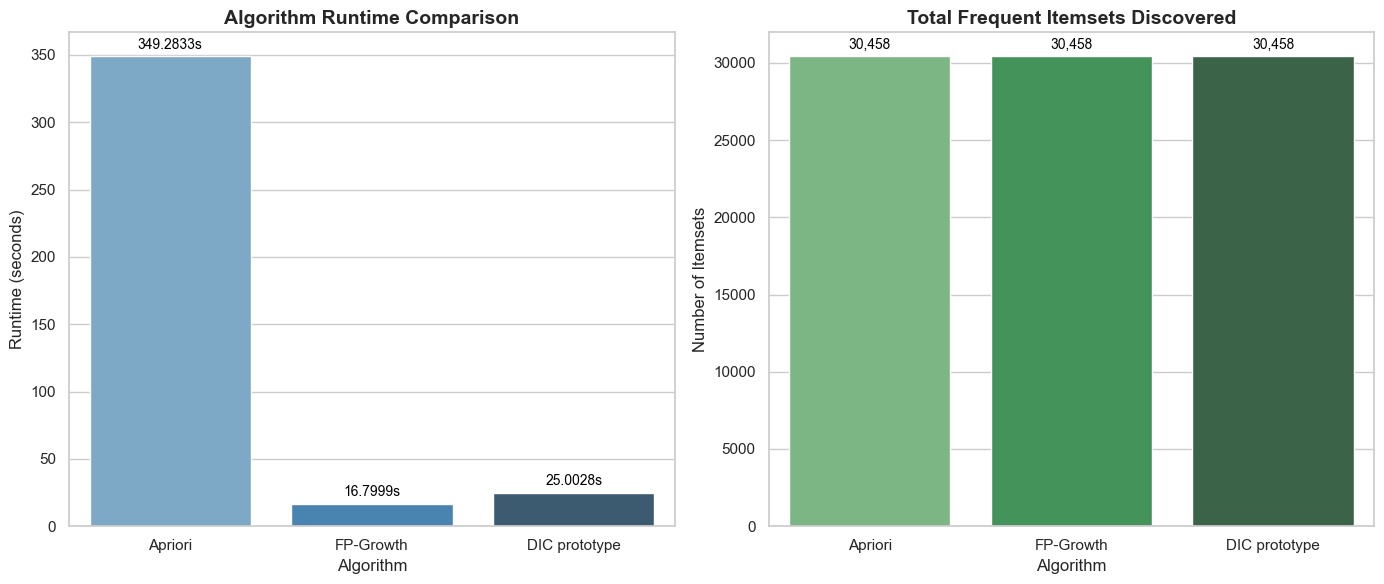

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns


# Set style for clean plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ---- Chart 1: Runtime Comparison ----
sns.barplot(
    data=comparison_df, 
    x="Algorithm", 
    y="Runtime (seconds)", 
    ax=axes[0], 
    palette="Blues_d"
)
axes[0].set_title("Algorithm Runtime Comparison", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Algorithm", fontsize=12)
axes[0].set_ylabel("Runtime (seconds)", fontsize=12)

# Add exact value labels on top of the bars
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(
        f"{height:.4f}s",
        (p.get_x() + p.get_width() / 2., height),
        ha="center", va="bottom",
        fontsize=10, color="black",
        xytext=(0, 3),
        textcoords="offset points"
    )

# ---- Chart 2: Total Frequent Itemsets Discovered ----
sns.barplot(
    data=comparison_df, 
    x="Algorithm", 
    y="Frequent itemsets", 
    ax=axes[1], 
    palette="Greens_d"
)
axes[1].set_title("Total Frequent Itemsets Discovered", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Algorithm", fontsize=12)
axes[1].set_ylabel("Number of Itemsets", fontsize=12)

# Add exact value labels on top of the bars
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(
        f"{int(height):,}",
        (p.get_x() + p.get_width() / 2., height),
        ha="center", va="bottom",
        fontsize=10, color="black",
        xytext=(0, 3),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

Execution Time Comparision

Itemset size distribution

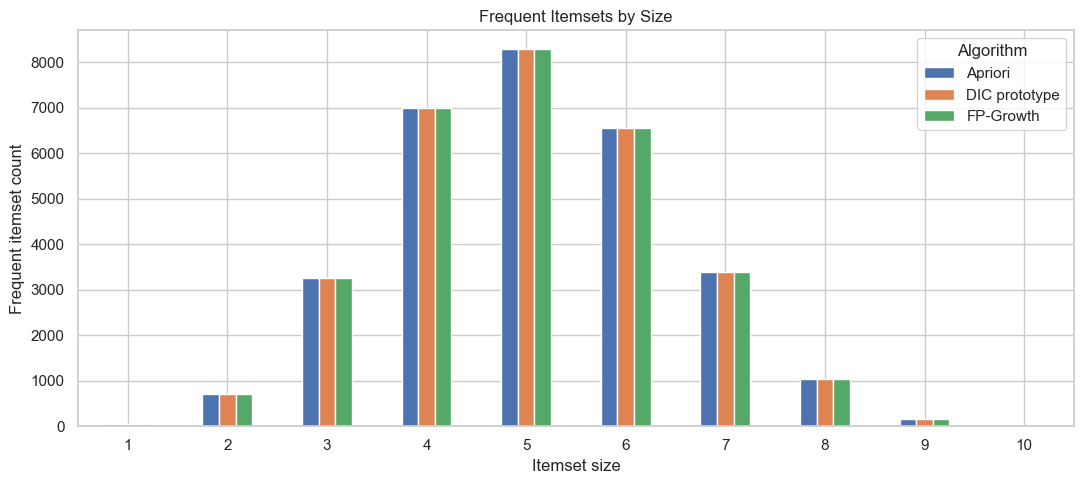

In [57]:

size_rows = []

for algorithm, (result, _) in results.items():
    if result.empty:
        continue

    counts = result["itemset_size"].value_counts().sort_index()

    for size, count in counts.items():
        size_rows.append({
            "Algorithm": algorithm,
            "Itemset size": size,
            "Count": count
        })

size_df = pd.DataFrame(size_rows)

if not size_df.empty:
    size_pivot = size_df.pivot(
        index="Itemset size",
        columns="Algorithm",
        values="Count"
    ).fillna(0)

    size_pivot.plot(
        kind="bar",
        figsize=(11, 5)
    )

    plt.ylabel("Frequent itemset count")
    plt.title("Frequent Itemsets by Size")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("No frequent itemsets found.")


Runtime vs Min-support

Running algorithms at minimum support = 20%
Running algorithms at minimum support = 15%
Running algorithms at minimum support = 10%


,Minimum support,Algorithm,Runtime (seconds),Frequent itemsets
0,0.20,Apriori,18.630243,845
1,0.20,FP-Growth,1.666811,845
2,0.20,DIC,0.795942,845
3,0.15,Apriori,29.309518,1739
4,0.15,FP-Growth,3.910291,1739
5,0.15,DIC,1.476711,1739
6,0.10,Apriori,60.898074,4594
7,0.10,FP-Growth,8.412204,4594
8,0.10,DIC,4.167132,4594


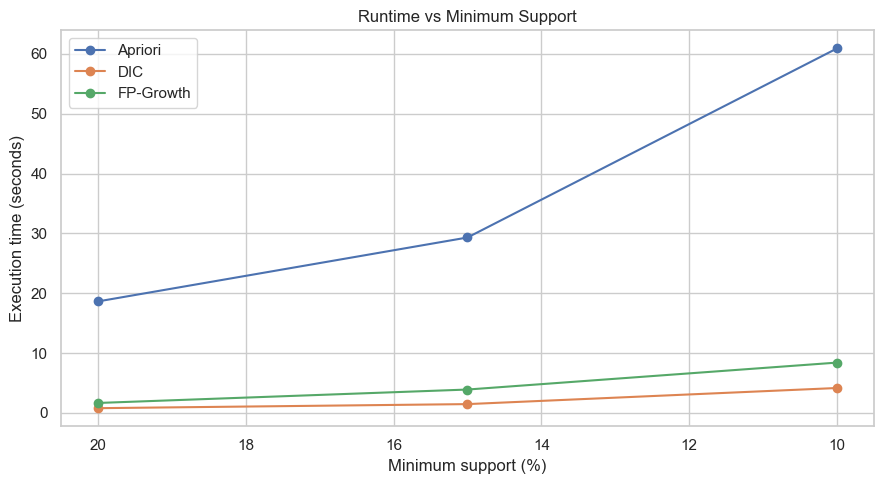

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

support_levels = [0.20, 0.15, 0.10]
support_rows = []

for support in support_levels:
    print(f"Running algorithms at minimum support = {support:.0%}")
    
    for algorithm, function in [
        ("Apriori", run_apriori),
        ("FP-Growth", run_fpgrowth),
        ("DIC", run_dic)
    ]:
        # Safely handle outputs whether functions return 2 or more items
        output = function(basket, support)
        if isinstance(output, (list, tuple)) and len(output) >= 2:
            result = output[0]
            elapsed = output[1]
        else:
            raise ValueError(f"{algorithm} function did not return a valid (result, elapsed) tuple.")

        support_rows.append({
            "Minimum support": support,
            "Algorithm": algorithm,
            "Runtime (seconds)": elapsed,
            "Frequent itemsets": len(result)
        })

# Create comparison dataframe
support_comparison = pd.DataFrame(support_rows)
display(support_comparison)

# Plotting Runtime vs Minimum Support
plt.figure(figsize=(9, 5))

for algorithm, group in support_comparison.groupby("Algorithm"):
    plt.plot(
        group["Minimum support"] * 100,
        group["Runtime (seconds)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Minimum support (%)")
plt.ylabel("Execution time (seconds)")
plt.title("Runtime vs Minimum Support")
plt.legend()
plt.gca().invert_xaxis()  # Inverts axis so support flows naturally from 20% down to 10%
plt.tight_layout()
plt.show()

In [76]:

fastest = comparison_df.loc[
    comparison_df["Runtime (seconds)"].idxmin()
]

print("PHASE 1: EXPERIMENTAL INFERENCES")
print("=" * 55)

print(
    f"Fastest measured implementation: {fastest['Algorithm']} "
    f"({fastest['Runtime (seconds)']:.4f} seconds)."
)

counts = comparison_df["Frequent itemsets"]

if counts.nunique() == 1:
    print("All three algorithms returned the same number of frequent itemsets.")
else:
    print("The algorithms returned different itemset counts.")
    print("Check itemset equality and support calculations before interpreting.")

if len(support_comparison):
    for algorithm, group in support_comparison.groupby("Algorithm"):
        ordered = group.sort_values("Minimum support")
        if len(ordered) >= 2:
            first = ordered.iloc[0]
            last = ordered.iloc[-1]

            print(
                f"{algorithm}: at {first['Minimum support']:.0%} support, "
                f"{int(first['Frequent itemsets'])} itemsets; "
                f"at {last['Minimum support']:.0%}, "
                f"{int(last['Frequent itemsets'])} itemsets."
            )

print("\nInterpretation:")
print("- Lower support usually increases the number of frequent itemsets.")
print("- Runtime depends on both the algorithm and dataset characteristics.")
print("- Compare exact itemsets and supports before comparing performance.")
print("- The DIC prototype runtime is not a canonical DIC benchmark.")

PHASE 1: EXPERIMENTAL INFERENCES
Fastest measured implementation: FP-Growth (16.7999 seconds).
All three algorithms returned the same number of frequent itemsets.
Apriori: at 10% support, 4594 itemsets; at 20%, 845 itemsets.
DIC: at 10% support, 4594 itemsets; at 20%, 845 itemsets.
FP-Growth: at 10% support, 4594 itemsets; at 20%, 845 itemsets.

Interpretation:
- Lower support usually increases the number of frequent itemsets.
- Runtime depends on both the algorithm and dataset characteristics.
- Compare exact itemsets and supports before comparing performance.
- The DIC prototype runtime is not a canonical DIC benchmark.


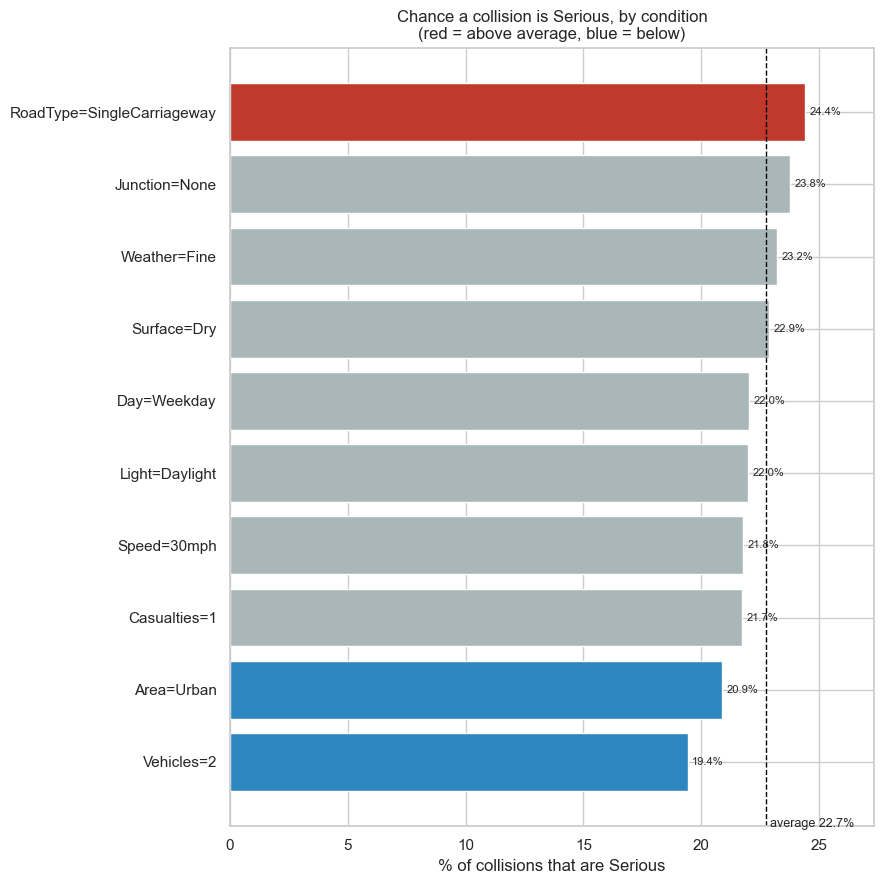

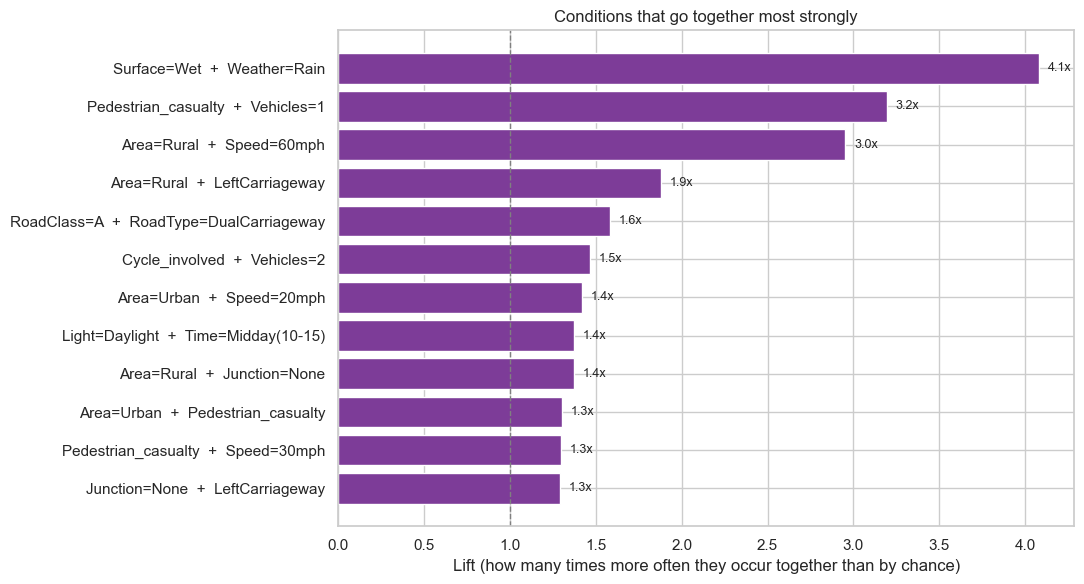

In [73]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt

# ---- load the Apriori itemsets (uses the table in memory; falls back to the CSV) ----
try:
    df = apriori_result.copy()
    df["items"] = df["itemsets"].apply(frozenset)
except NameError:
    df = pd.read_csv("apriori_result.csv")          # in Colab: upload the file first
    df["items"] = df["itemsets"].apply(lambda s: frozenset(x.strip() for x in s.strip("{}").split(", ")))

sup = dict(zip(df["items"], df["support"]))
single = {next(iter(k)): v for k, v in sup.items() if len(k) == 1}
fmt = lambda s: "{" + ", ".join(sorted(s)) + "}"

# ---------- Chart 1: chance of a Serious collision under each condition ----------
base = single["Severity=Serious"]
rows = []
for it, v in single.items():
    if it.startswith("Severity="):
        continue
    ps = sup.get(frozenset([it, "Severity=Serious"]))
    if ps:
        rows.append((it, ps / v))
t = pd.DataFrame(rows, columns=["item", "p"]).sort_values("p")
fig, ax = plt.subplots(figsize=(9, 9))
colors = ["#c0392b" if p > base * 1.05 else "#2e86c1" if p < base * 0.95 else "#aab7b8" for p in t["p"]]
ax.barh(t["item"], t["p"] * 100, color=colors)
ax.axvline(base * 100, color="black", ls="--", lw=1)
ax.text(base * 100 + 0.2, -0.9, f"average {base:.1%}", fontsize=9)
for y, p in enumerate(t["p"]):
    ax.text(p * 100 + 0.2, y, f"{p:.1%}", va="center", fontsize=8)
ax.set_xlabel("% of collisions that are Serious")
ax.set_title("Chance a collision is Serious, by condition\n(red = above average, blue = below)")
ax.set_xlim(0, t["p"].max() * 100 * 1.12)
plt.tight_layout(); plt.show()

# ---------- Chart 2: strongest co-occurring pairs ----------
pairs = []
for it, s in sup.items():
    if len(it) == 2:
        a, b = sorted(it)
        pairs.append((f"{a}  +  {b}", s / (single[a] * single[b])))
P = pd.DataFrame(pairs, columns=["pair", "lift"]).sort_values("lift", ascending=False)
top = P.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top["pair"], top["lift"], color="#7d3c98")
for y, l in enumerate(top["lift"]):
    ax.text(l + 0.05, y, f"{l:.1f}x", va="center", fontsize=9)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Lift (how many times more often they occur together than by chance)")
ax.set_title("Conditions that go together most strongly")
plt.tight_layout(); plt.show()

# ---------- Chart 3: what do pedestrian / cyclist / run-off-road collisions look like? ----------
def best_rules(cons, top=5, max_ante=3, gap=0.97, min_lift=1.15):
    s_sup = single[cons]
    rules = {}
    for it, s in sup.items():
        if cons in it and 2 <= len(it) <= max_ante + 1:
            a = it - {cons}
            if any(x.startswith("Severity=") for x in a):
                continue
            conf = s / sup[a]
            rules[a] = (conf, conf / s_sup)
    rows = []
    for a, (c, l) in rules.items():
        if l < min_lift:
            continue
        if any(rules.get(frozenset(sub), (0, 0))[1] >= gap * l
               for r in range(1, len(a)) for sub in itertools.combinations(a, r)):
            continue
        rows.append((fmt(a), c, l))
    return sorted(rows, key=lambda x: -x[2])[:top]

#

Generate Association Rules

In [77]:

from mlxtend.frequent_patterns import association_rules

MIN_CONFIDENCE = 0.70

def generate_rules(frequent_itemsets, min_confidence=0.70):
    if frequent_itemsets.empty:
        return pd.DataFrame()

    # association_rules requires support and itemsets columns
    rules = association_rules(
        frequent_itemsets[["support", "itemsets"]],
        metric="confidence",
        min_threshold=min_confidence
    )

    if rules.empty:
        return rules

    # Keep useful metrics and readable item names
    rules["antecedents"] = rules["antecedents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )
    rules["consequents"] = rules["consequents"].apply(
        lambda x: ", ".join(sorted(map(str, x)))
    )

    columns = [
        "antecedents", "consequents",
        "antecedent support", "consequent support",
        "support", "confidence", "lift",
        "leverage", "conviction"
    ]

    return rules[columns].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)


apriori_rules = generate_rules(apriori_result, MIN_CONFIDENCE)
fp_rules = generate_rules(fp_result, MIN_CONFIDENCE)
dic_rules = generate_rules(dic_result, MIN_CONFIDENCE)

print("Apriori rules:", len(apriori_rules))
print("FP-Growth rules:", len(fp_rules))
print("DIC rules:", len(dic_rules))

print("\nTop Apriori rules:")
display(apriori_rules.head(20))

print("\nTop FP-Growth rules:")
display(fp_rules.head(20))

print("\nTop DIC rules:")
display(dic_rules.head(20))


Apriori rules: 5815
FP-Growth rules: 143999
DIC rules: 143999

Top Apriori rules:


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,"Area=Urban, Light=Daylight, Vehicles=1",Pedestrian_casualty,0.134588,0.176579,0.103625,0.769942,4.360326,0.079860,3.579185
1,"Area=Urban, RoadType=SingleCarriageway, Vehicl...",Pedestrian_casualty,0.153021,0.176579,0.117061,0.764998,4.332332,0.090040,3.503897
2,"Area=Urban, Day=Weekday, Vehicles=1",Pedestrian_casualty,0.150223,0.176579,0.114787,0.764108,4.327291,0.088261,3.490674
3,"Area=Urban, Speed=30mph, Vehicles=1",Pedestrian_casualty,0.131997,0.176579,0.100129,0.758568,4.295917,0.076821,3.410576
4,Pedestrian_casualty,"Area=Urban, Casualties=1, Vehicles=1",0.176579,0.182608,0.138232,0.782835,4.286981,0.105988,3.763930
5,"Area=Urban, Casualties=1, Vehicles=1",Pedestrian_casualty,0.182608,0.176579,0.138232,0.756990,4.286981,0.105988,3.388431
6,"Pedestrian_casualty, Speed=30mph","Area=Urban, Vehicles=1",0.118964,0.197176,0.100129,0.841670,4.268620,0.076672,5.070584
7,"Area=Urban, Surface=Dry, Vehicles=1",Pedestrian_casualty,0.144861,0.176579,0.108690,0.750309,4.249143,0.083111,3.297761
8,"Pedestrian_casualty, Severity=Slight","Area=Urban, Vehicles=1",0.120487,0.197176,0.100880,0.837273,4.246317,0.077123,4.933556
9,"Casualties=1, Pedestrian_casualty","Area=Urban, Vehicles=1",0.165750,0.197176,0.138232,0.833981,4.229624,0.105550,4.835741



Top FP-Growth rules:


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,Speed=70mph,"Area=Rural, RoadType=DualCarriageway",0.054998,0.061979,0.041664,0.757548,12.222695,0.038255,3.868892
1,Speed=70mph,"Junction=None, RoadType=DualCarriageway",0.054998,0.095241,0.044932,0.816975,8.577989,0.039694,4.943369
2,"Junction=None, LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.059481,0.100037,0.042978,0.722542,7.222723,0.037027,3.243602
3,"LeftCarriageway, RoadType=SingleCarriageway, V...",HitObjectOffRoad,0.059289,0.100037,0.042824,0.722297,7.220271,0.036893,3.240738
4,"LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.078210,0.100037,0.056400,0.721134,7.208646,0.048576,3.227222
5,"LeftCarriageway, Vehicles=1, Weather=Fine",HitObjectOffRoad,0.058278,0.100037,0.041825,0.717683,7.174151,0.035995,3.187776
6,"Casualties=1, LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.062787,0.100037,0.044743,0.712625,7.123585,0.038462,3.131664
7,"HitObjectOffRoad, RoadType=SingleCarriageway, ...","LeftCarriageway, Weather=Fine",0.046295,0.134242,0.043856,0.947313,7.056776,0.037641,16.432135
8,"HitObjectOffRoad, Surface=Dry","LeftCarriageway, Weather=Fine",0.062020,0.134242,0.058576,0.944476,7.035640,0.050250,15.592460
9,"Casualties=1, HitObjectOffRoad, Surface=Dry","LeftCarriageway, Weather=Fine",0.043881,0.134242,0.041243,0.939890,7.001479,0.035353,14.402897



Top DIC rules:


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,Speed=70mph,"Area=Rural, RoadType=DualCarriageway",0.054998,0.061979,0.041664,0.757548,12.222695,0.038255,3.868892
1,Speed=70mph,"Junction=None, RoadType=DualCarriageway",0.054998,0.095241,0.044932,0.816975,8.577989,0.039694,4.943369
2,"Junction=None, LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.059481,0.100037,0.042978,0.722542,7.222723,0.037027,3.243602
3,"LeftCarriageway, RoadType=SingleCarriageway, V...",HitObjectOffRoad,0.059289,0.100037,0.042824,0.722297,7.220271,0.036893,3.240738
4,"LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.078210,0.100037,0.056400,0.721134,7.208646,0.048576,3.227222
5,"LeftCarriageway, Vehicles=1, Weather=Fine",HitObjectOffRoad,0.058278,0.100037,0.041825,0.717683,7.174151,0.035995,3.187776
6,"Casualties=1, LeftCarriageway, Vehicles=1",HitObjectOffRoad,0.062787,0.100037,0.044743,0.712625,7.123585,0.038462,3.131664
7,"HitObjectOffRoad, RoadType=SingleCarriageway, ...","LeftCarriageway, Weather=Fine",0.046295,0.134242,0.043856,0.947313,7.056776,0.037641,16.432135
8,"HitObjectOffRoad, Surface=Dry","LeftCarriageway, Weather=Fine",0.062020,0.134242,0.058576,0.944476,7.035640,0.050250,15.592460
9,"Casualties=1, HitObjectOffRoad, Surface=Dry","LeftCarriageway, Weather=Fine",0.043881,0.134242,0.041243,0.939890,7.001479,0.035353,14.402897


Compare Association Rules

In [78]:

rule_results = {
    "Apriori": apriori_rules,
    "FP-Growth": fp_rules,
    "DIC": dic_rules
}

rule_comparison = []

for algorithm, rules in rule_results.items():
    if rules.empty:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": 0,
            "Mean confidence": np.nan,
            "Mean lift": np.nan,
            "Maximum lift": np.nan,
            "Rules with lift > 1": 0
        })
    else:
        rule_comparison.append({
            "Algorithm": algorithm,
            "Rules": len(rules),
            "Mean confidence": rules["confidence"].mean(),
            "Mean lift": rules["lift"].mean(),
            "Maximum lift": rules["lift"].max(),
            "Rules with lift > 1": (rules["lift"] > 1).sum()
        })

rule_comparison_df = pd.DataFrame(rule_comparison)

display(
    rule_comparison_df.style.format({
        "Mean confidence": "{:.3f}",
        "Mean lift": "{:.3f}",
        "Maximum lift": "{:.3f}"
    })
)

,Algorithm,Rules,Mean confidence,Mean lift,Maximum lift,Rules with lift > 1
0,Apriori,5815,0.797,1.125,4.360,4789
1,FP-Growth,143999,0.801,1.304,12.223,132396
2,DIC,143999,0.801,1.304,12.223,132396


Plot Association Rule Metrics

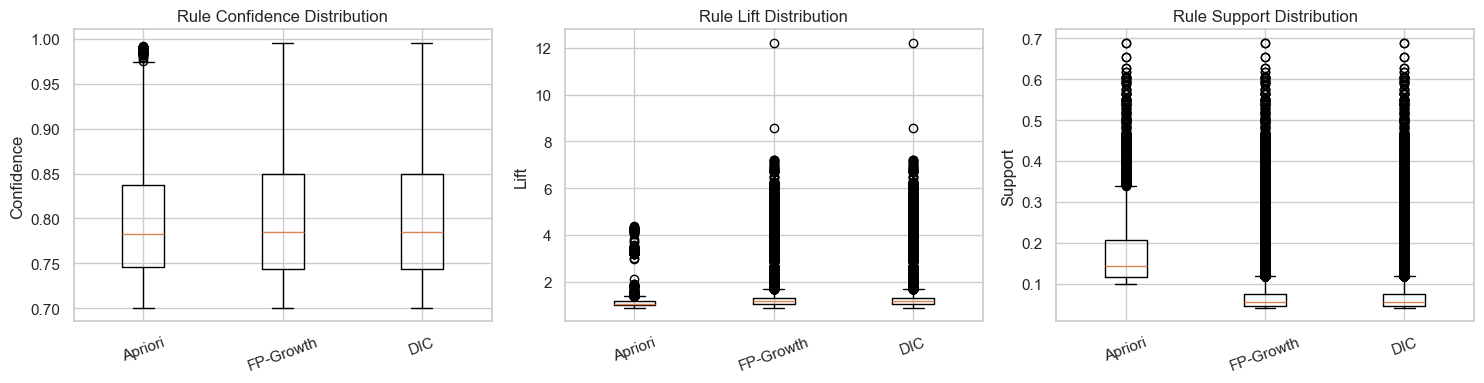

In [79]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("confidence", "Confidence"),
    ("lift", "Lift"),
    ("support", "Support")
]

for ax, (metric, title) in zip(axes, metrics):
    values = [
        rules[metric].dropna().values
        for rules in rule_results.values()
        if not rules.empty
    ]

    labels = [
        name for name, rules in rule_results.items()
        if not rules.empty
    ]

    if values:
        ax.boxplot(values, tick_labels=labels)
        ax.set_title(f"Rule {title} Distribution")
        ax.set_ylabel(title)
        ax.tick_params(axis="x", rotation=20)
    else:
        ax.set_title(f"No rules available for {title}")

plt.tight_layout()
plt.show()


Extract rules involving severity = Fatal

In [82]:
import pandas as pd

def severity_rules(rules, target_severity="Serious"):
    """
    Filters association rules for a specific severity target 
    (e.g., 'Fatal', 'Serious', 'Slight') in the consequents.
    """
    if rules.empty:
        return pd.DataFrame()

    pattern = rf"Severity={target_severity}"
    
    filtered = rules[
        rules["consequents"].astype(str).str.contains(
            pattern,
            regex=True,
            na=False
        )
    ].sort_values(
        ["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)
    
    return filtered

# ---- Run and inspect for each severity type ----
for sev in ["Serious", "Slight", "Fatal"]:
    print(f"\n{'='*40}")
    print(f"Top Rules predicting: Severity = {sev}")
    print(f"{'='*40}")
    
    # Example using Apriori rules (repeat for fp_rules / dic_rules as needed)
    res = severity_rules(apriori_rules, target_severity=sev)
    
    if res.empty:
        print(f"⚠️ No association rules found for Severity={sev} at this support threshold.")
        print(f"   (Justification: Likely due to low support/volume for this class relative to min_support).")
    else:
        display(res.head(10))


Top Rules predicting: Severity = Serious
⚠️ No association rules found for Severity=Serious at this support threshold.
   (Justification: Likely due to low support/volume for this class relative to min_support).

Top Rules predicting: Severity = Slight


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
0,Speed=20mph,"Area=Urban, Casualties=1, Severity=Slight",0.171475,0.454118,0.120987,0.705567,1.553709,0.043117,1.854012
1,"Casualties=1, Speed=20mph","Area=Urban, Severity=Slight",0.156091,0.526389,0.120987,0.775108,1.472501,0.038823,2.105947
2,"Day=Weekday, Speed=20mph","Area=Urban, Severity=Slight",0.130477,0.526389,0.100717,0.771913,1.466432,0.032035,2.076449
3,Speed=20mph,"Area=Urban, Severity=Slight",0.171475,0.526389,0.131935,0.769412,1.461682,0.041672,2.053933
4,"Speed=20mph, Surface=Dry","Area=Urban, Severity=Slight",0.131843,0.526389,0.100970,0.765831,1.454879,0.031569,2.022524
5,"Speed=20mph, Weather=Fine","Area=Urban, Severity=Slight",0.135293,0.526389,0.102928,0.760780,1.445283,0.031712,1.979819
6,"Time=Midday(10-15), Vehicles=2","Light=Daylight, Severity=Slight",0.225747,0.550431,0.177383,0.785760,1.427535,0.053125,2.098433
7,"Area=Urban, Time=Midday(10-15)","Light=Daylight, Severity=Slight",0.236808,0.550431,0.185166,0.781924,1.420565,0.054819,2.061518
8,"Speed=30mph, Time=Midday(10-15)","Light=Daylight, Severity=Slight",0.187939,0.550431,0.145184,0.772502,1.403449,0.041736,1.976145
9,"Casualties=1, Time=Midday(10-15)","Light=Daylight, Severity=Slight",0.290778,0.550431,0.221618,0.762156,1.384652,0.061565,1.890180



Top Rules predicting: Severity = Fatal
⚠️ No association rules found for Severity=Fatal at this support threshold.
   (Justification: Likely due to low support/volume for this class relative to min_support).


In [81]:
import time, math
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

# ---------- 1. settings ----------
MIN_SUPPORT = 0.10     # start here, lower later
MAX_LEN = 4            # biggest itemset size to look for

# ---------- 2. get the True/False table ----------
try:
    df = basket.astype(bool)                     # if you already have 'basket'
except NameError:
    te = TransactionEncoder()                    # else build it from 'transactions' (list of lists)
    df = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

print("Transactions:", len(df), "| Items:", df.shape[1])

# ---------- 3. helper ----------
def tidy(result):
    result["itemset_size"] = result["itemsets"].apply(len)
    return result.sort_values(["itemset_size", "support"], ascending=[True, False]).reset_index(drop=True)

# ---------- 4. Apriori ----------
t = time.perf_counter()
apriori_result = tidy(apriori(df, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN, low_memory=True))
apriori_time = time.perf_counter() - t
print(f"Apriori   : {len(apriori_result):>6} itemsets in {apriori_time:.1f}s")

# ---------- 5. FP-Growth ----------
t = time.perf_counter()
fp_result = tidy(fpgrowth(df, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN))
fp_time = time.perf_counter() - t
print(f"FP-Growth : {len(fp_result):>6} itemsets in {fp_time:.1f}s")

# ---------- 6. DIC (bitset version) ----------
def run_dic(df, min_support, max_len):
    cols = list(df.columns)
    M = df.to_numpy(dtype=bool)
    n, k_items = M.shape
    min_count = math.ceil(min_support * n)
    mask = [int.from_bytes(np.packbits(M[:, j], bitorder="little").tobytes(), "little") for j in range(k_items)]

    freq, level = {}, {}
    for j in range(k_items):
        c = mask[j].bit_count()
        if c >= min_count:
            freq[(j,)] = c
            level[(j,)] = mask[j]

    k = 2
    while level and k <= max_len:
        cur = sorted(level)
        prev = set(cur)
        nxt = {}
        for a in range(len(cur)):
            for b in range(a + 1, len(cur)):
                if cur[a][:-1] != cur[b][:-1]:
                    break
                cand = cur[a] + (cur[b][-1],)
                if any(cand[:i] + cand[i+1:] not in prev for i in range(k - 2)):
                    continue
                m = level[cur[a]] & mask[cur[b][-1]]
                c = m.bit_count()
                if c >= min_count:
                    freq[cand] = c
                    nxt[cand] = m
        level, k = nxt, k + 1

    rows = [{"support": c / n, "itemsets": frozenset(cols[i] for i in it)} for it, c in freq.items()]
    return tidy(pd.DataFrame(rows, columns=["support", "itemsets"]))

t = time.perf_counter()
dic_result = run_dic(df, MIN_SUPPORT, MAX_LEN)
dic_time = time.perf_counter() - t
print(f"DIC       : {len(dic_result):>6} itemsets in {dic_time:.1f}s")

# ---------- 7. check they agree ----------
same = (set(apriori_result.itemsets) == set(fp_result.itemsets) == set(dic_result.itemsets))
print("All three give the same itemsets:", same)

display(apriori_result.head(20))

Transactions: 513708 | Items: 70
Apriori   :   2726 itemsets in 28.6s


KeyboardInterrupt: 